# UFC — Golpes significativos e decisões
**Igor de Andrade Albuquerque · Fase 2 · BI e Analytics**

Este notebook reproduz a coleta versionada, limpeza, banco SQLite, KPIs, modelo e painéis. No Colab, use **Ambiente de execução → Executar tudo**. Não exige GPU nem montagem do Drive. A primeira execução baixa três CSVs públicos (aproximadamente 10 MB).

**Pergunta de negócio:** com que frequência o líder em golpes significativos vence a decisão e como isso muda entre unânimes e divididas? O usuário é um analista de cobertura esportiva. O uso proposto é conferir afirmações e escolher casos para análise editorial.

**Escopo:** UFC, 2022–2024, formato previsto 3 × 5 minutos, três rounds completos, decisões unânimes ou divididas e vencedor identificável. Os empates na contagem permanecem nos KPIs e ficam fora do classificador.

**Limites:** os indicadores não medem erro ou viés dos juízes. A previsão usa estatísticas de combates concluídos; não é pré-luta. A conferência externa das 12 fichas da amostra ficou pendente por bloqueio de acesso; os testes internos foram concluídos.

## 1. Preparação do ambiente
A célula cria uma pasta isolada quando os arquivos do repositório não estão presentes. As fontes do projeto estão incorporadas para permitir executar este notebook sozinho. Dependências: pandas, numpy, matplotlib, scikit-learn e IPython (incluídas no Colab).

In [1]:
from pathlib import Path
import os, sys, json
import importlib.metadata as metadata
import subprocess, re
requirements = {"numpy": ("numpy", (1,26)), "pandas": ("pandas", (2,2)), "sklearn": ("scikit-learn", (1,4)), "scipy": ("scipy", (1,11)), "matplotlib": ("matplotlib", (3,8))}
missing=[]
for module,(package,minimum) in requirements.items():
    try:
        installed=tuple(int(x) for x in metadata.version(package).split(".")[:2])
        if installed < minimum: missing.append(package+">="+".".join(map(str,minimum)))
    except metadata.PackageNotFoundError: missing.append(package+">="+".".join(map(str,minimum)))
if missing: subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*missing])
ROOT = Path.cwd()
if not (ROOT / 'data/raw/ufc_event_details.csv').exists():
    ROOT = (Path('/content/ufc_bi') if Path('/content').exists() else ROOT / 'ufc_bi_runtime')
for folder in ['sql','src','data/raw','data/processed','outputs','tests','docs','notebooks']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
SOURCES = {'src/__init__.py': '"""Projeto UFC de BI e Analytics."""\n', 'src/analytics.py': '"""Analytics: classificação retrospectiva do resultado de decisões, após três rounds.\n\nPergunta: dado o desempenho nos três rounds, qual a probabilidade de o líder\nem golpes significativos ser o vencedor oficial?\n\nEsta NÃO é uma previsão pré-luta. O modelo usa estatísticas do combate já\nconcluído e nunca usa vencedor, método da decisão, votos ou placares como entrada.\n\nProtocolo de validação (temporal, sem vazamento de dados):\n    treino 2022  ->  escolha de C em 2023 (menor log loss)  ->  reajuste em 2022-23  ->  teste em 2024.\nO conjunto de 2024 só é avaliado depois de fixados todos os hiperparâmetros.\n\nExecute da raiz:  python -m src.analytics\n"""\nimport json\nimport platform\n\nimport numpy as np\nimport pandas as pd\nimport sklearn\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (accuracy_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,\n                             f1_score, log_loss, precision_score, recall_score, roc_auc_score)\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import StandardScaler\n\nfrom .pipeline import ROOT\n\n# Sete diferenças "líder menos adversário" calculadas em pipeline.build_bout_rows().\nFEATURES = [\'sig_margin\', \'attempt_margin\', \'accuracy_margin\', \'round_margin\',\n            \'td_landed_margin\', \'kd_margin\', \'control_seconds_margin\']\n\n# Grade de regularização testada (C menor = regularização mais forte).\nC_GRID = (0.1, 1.0, 10.0)\nTHRESHOLD = 0.5  # limiar de classificação, fixado a priori\n\n\ndef metrics(y, p):\n    """Métricas de classificação binária a partir do alvo `y` e das probabilidades `p`.\n\n    Alvo 1 = concordância; alvo 0 = divergência. Inclui métricas de probabilidade\n    (AUC, log loss, Brier) e a matriz de confusão [[VN, FP], [FN, VP]].\n    """\n    predicted = (p >= THRESHOLD).astype(int)\n    return dict(n=len(y),\n                accuracy=float(accuracy_score(y, predicted)),\n                balanced_accuracy=float(balanced_accuracy_score(y, predicted)),\n                auc=float(roc_auc_score(y, p)),\n                log_loss=float(log_loss(y, p, labels=[0, 1])),\n                brier=float(brier_score_loss(y, p)),\n                precision_concordance=float(precision_score(y, predicted, zero_division=0)),\n                recall_concordance=float(recall_score(y, predicted, zero_division=0)),\n                f1_concordance=float(f1_score(y, predicted, zero_division=0)),\n                recall_divergence=float(recall_score(y, predicted, pos_label=0, zero_division=0)),\n                confusion_matrix=confusion_matrix(y, predicted, labels=[0, 1]).tolist())\n\n\ndef estimator(c):\n    """Pipeline do scikit-learn: imputação pela mediana -> padronização -> regressão logística.\n\n    As transformações são ajustadas apenas nos dados de treino (sem vazamento).\n    """\n    return Pipeline([(\'imputer\', SimpleImputer(strategy=\'median\')),\n                     (\'scaler\', StandardScaler()),\n                     (\'model\', LogisticRegression(C=c, max_iter=3000, random_state=42))])\n\n\ndef run():\n    """Treina, seleciona, testa e exporta métricas, previsões e parâmetros do modelo."""\n    b = pd.read_csv(ROOT / \'data/processed/bouts.csv\')\n    b = b[b.status.isin([\'C\', \'D\'])].copy()          # empates não têm líder: fora só da classificação\n    b[\'target\'] = (b.status == \'C\').astype(int)\n\n    # Divisão temporal por ano; a asserção impede sobreposição de datas entre as partes.\n    train, val, test = b[b.year == 2022], b[b.year == 2023], b[b.year == 2024]\n    assert train.date.max() < val.date.min() < test.date.min()\n\n    # 1) Seleção de hiperparâmetro em 2023 (critério: menor log loss; empate -> menor C).\n    trials = []\n    for c in C_GRID:\n        model = estimator(c).fit(train[FEATURES], train.target)\n        trials.append({\'C\': c, **metrics(val.target, model.predict_proba(val[FEATURES])[:, 1])})\n    chosen = min(trials, key=lambda x: (x[\'log_loss\'], x[\'C\']))[\'C\']\n\n    # 2) Reajuste em 2022-2023 e avaliação única em 2024.\n    dev = pd.concat([train, val]).sort_values(\'date\')\n    model = estimator(chosen).fit(dev[FEATURES], dev.target)\n    probabilities = model.predict_proba(test[FEATURES])[:, 1]\n\n    # Baseline: probabilidade constante = taxa de concordância do treino final (76,51%).\n    baseline = np.full(len(test), dev.target.mean())\n\n    result = {\n        \'task\': \'Probabilidade de o líder único em golpes significativos vencer a decisão, dados os três rounds completos.\',\n        \'prediction_time\': \'Após os três rounds; avaliação retrospectiva em decisões unânimes/divididas. Não é previsão pré-luta nem serviço ao vivo.\',\n        \'target\': \'1 = concordância; 0 = divergência\', \'features\': FEATURES, \'validation\': trials, \'selected_C\': chosen,\n        \'split\': {\'train_2022\': len(train), \'validation_2023\': len(val),\n                  \'final_train_2022_2023\': len(dev), \'test_2024\': len(test)},\n        \'test_model\': metrics(test.target, probabilities), \'test_baseline\': metrics(test.target, baseline),\n        \'baseline_probability\': float(dev.target.mean()),\n        \'environment\': {\'python\': platform.python_version(), \'numpy\': np.__version__,\n                        \'pandas\': pd.__version__, \'sklearn\': sklearn.__version__}}\n\n    # Previsões individuais (auditáveis) e desempenho por tipo de decisão.\n    pred = test[[\'bout_id\', \'date\', \'method\', \'leader\', \'other\', \'winner\', \'status\', \'target\']].copy()\n    pred[\'probability\'] = probabilities\n    pred[\'predicted\'] = (probabilities >= THRESHOLD).astype(int)\n    pred[\'baseline_probability\'] = baseline\n    pred.to_csv(ROOT / \'outputs/predictions_2024.csv\', index=False)\n    result[\'test_by_method\'] = {str(m): metrics(g.target, g.probability.to_numpy()) for m, g in pred.groupby(\'method\')}\n    (ROOT / \'outputs/model_metrics.json\').write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n\n    # Parâmetros em JSON transparente (evita desserialização de pickle) e permitem\n    # reproduzir a inferência manualmente: logit = coef . ((x - mean) / scale) + intercept.\n    artifact = {\'features\': FEATURES, \'imputer\': model[\'imputer\'].statistics_.tolist(),\n                \'mean\': model[\'scaler\'].mean_.tolist(), \'scale\': model[\'scaler\'].scale_.tolist(),\n                \'coef\': model[\'model\'].coef_[0].tolist(), \'intercept\': float(model[\'model\'].intercept_[0]),\n                \'training_last_date\': dev.date.max(), \'C\': chosen}\n    (ROOT / \'outputs/model.json\').write_text(json.dumps(artifact, indent=2), encoding=\'utf-8\')\n\n    # Verificação cruzada: o JSON reproduz exatamente as probabilidades do scikit-learn.\n    x = ((test[FEATURES].fillna(dict(zip(FEATURES, artifact[\'imputer\']))) - artifact[\'mean\']) / artifact[\'scale\']).to_numpy()\n    logits = x @ np.array(artifact[\'coef\']) + artifact[\'intercept\']\n    assert np.allclose(1 / (1 + np.exp(-logits)), probabilities)\n    print(json.dumps(result, ensure_ascii=False, indent=2))\n    return result\n\n\nif __name__ == \'__main__\':\n    run()\n', 'src/conclusions.py': '"""Gera a conclusão da Fase 1 (Markdown e HTML) diretamente dos KPIs calculados.\n\nOs números do texto nunca são digitados à mão: vêm de outputs/kpis.json, o que\nimpede divergência entre relatório, painel e dados. Se os dados deixarem de\nsustentar H1/H2, a geração é interrompida em vez de produzir texto enganoso.\n"""\nimport json\nfrom html import escape\nfrom .pipeline import ROOT\n\n\ndef build():\n    """Monta os parágrafos a partir dos KPIs; grava docs/CONCLUSAO.md e devolve (markdown, html)."""\n    k = json.loads((ROOT / \'outputs/kpis.json\').read_text())\n    a, u, d = k[\'all\'], k[\'by_method\'][\'Unânime\'], k[\'by_method\'][\'Dividida\']\n    fmt = lambda x: f\'{x:.2f}\'.replace(\'.\', \',\')\n    annual = [k[\'by_year_method\'][f\'{y} Unânime\'][\'concordance\'] -\n              k[\'by_year_method\'][f\'{y} Dividida\'][\'concordance\'] for y in (2022, 2023, 2024)]\n    # Trava de coerência: a redação assume H1 e H2 apoiadas descritivamente.\n    supported = a[\'concordance\'] > 50 and u[\'concordance\'] > d[\'concordance\']\n    if not supported:\n        raise ValueError(\'Os dados não sustentam a conclusão desta versão; revisar o texto.\')\n    # Cada item é (título, texto); os percentuais usam vírgula decimal (pt-BR) via fmt().\n    paragraphs = [\n        (\'Resposta à pergunta central\',\n         f\'Sim, liderar em golpes significativos conectados foi um indicador associado à vitória nas decisões analisadas. \'\n         f\'O líder venceu {a["C"]} das {a["C"] + a["D"]} lutas classificáveis ({fmt(a["concordance"])}%) \'\n         f\'e perdeu {a["D"]} ({fmt(a["divergence"])}%). Portanto, a liderança acompanhou a vitória na maioria dos casos, \'\n         \'mas não garantiu o resultado. Esta conclusão descreve o UFC de 2022–2024, com três rounds completos e decisão unânime ou dividida.\'),\n        (\'H1 recebe apoio descritivo\',\n         f\'A concordância de {fmt(a["concordance"])}% superou em {fmt(k["H1_excess_pp"])} pontos percentuais \'\n         \'a referência de 50% definida na Fase 1. Escolher o líder em golpes acertou mais resultados históricos que a referência \'\n         \'de escolher aleatoriamente um dos dois atletas. A inferência exploratória complementar é apresentada separadamente e não muda o critério descritivo planejado.\'),\n        (\'H2 recebe apoio descritivo\',\n         f\'Nas decisões unânimes, o líder venceu {u["C"]}/{u["C"] + u["D"]} lutas ({fmt(u["concordance"])}%); \'\n         f\'nas divididas, {d["C"]}/{d["C"] + d["D"]} ({fmt(d["concordance"])}%). A diferença foi de \'\n         f\'{fmt(k["H2_difference_pp"])} pontos percentuais a favor das unânimes. A mesma direção apareceu em \'\n         f\'2022, 2023 e 2024: {", ".join(fmt(x) for x in annual)} pontos percentuais, respectivamente. \'\n         \'A contagem, assim, acompanhou menos frequentemente o vencedor nas decisões divididas.\'),\n        (\'Empates e robustez\',\n         f\'As {a["n"]} lutas válidas incluem {a["E"]} empates em golpes, mantidos no painel e retirados apenas \'\n         f\'do denominador da concordância. A cobertura classificável foi {fmt(a["coverage"])}%. \'\n         f\'Atribuir todos os empates aos extremos produz {fmt(a["sensitivity_low"])}% a {fmt(a["sensitivity_high"])}% \'\n         \'de concordância no total válido, ainda acima de 50%. A direção de H2 também permanece nas atribuições extremas. \'\n         \'Esses limites são uma análise de sensibilidade, não intervalos de confiança.\'),\n        (\'O que significa fazer diferença\',\n         \'Os resultados mostram utilidade da liderança em golpes para interpretar o resultado histórico. Não quantificam \'\n         \'o efeito causal de um golpe adicional, o peso isolado da contagem no voto de cada juiz ou a probabilidade de uma \'\n         \'luta futura. A base não contém os votos individuais por round; as divergências não demonstram erro ou viés de arbitragem. \'\n         \'Também não se conclui que vencer a contagem de um round equivale a vencê-lo nos cartões.\'),\n        (\'Aplicação para o analista de cobertura esportiva\',\n         f\'Usar a contagem como evidência contextual, informando período, tipo de decisão e denominador. Nas divididas, \'\n         f\'{d["D"]}/{d["C"] + d["D"]} lutas ({fmt(d["divergence"])}%) tiveram vitória do atleta com menos golpes, \'\n         \'o que exige cuidado ao interpretar apenas o total. O caso Holland × Della Maddalena ilustra uma dessas divergências; \'\n         \'a conclusão provém do conjunto de lutas, não desse exemplo.\'),\n        (\'Cumprimento dos objetivos da Fase 1\',\n         \'A base relacional foi integrada; concordâncias, divergências, empates e denominadores foram calculados; \'\n         \'as decisões foram comparadas no conjunto e em cada ano; o painel permite consultar luta e rounds. \'\n         \'O quarto objetivo específico permanece parcialmente atendido: as consultas foram reconciliadas internamente, \'\n         \'mas a conferência dos campos das 12 fichas oficiais segue pendente por bloqueio de acesso. \'\n         \'Os resultados referem-se ao espelho versionado e devem ser revistos se essa conferência identificar discrepâncias.\'),\n        (\'Papel complementar do Analytics\',\n         \'O modelo com sete variáveis acrescenta uma análise preditiva retrospectiva exigida na Fase 2. \'\n         \'Sua melhora agregada sobre a regra de escolher o líder não mede a contribuição isolada dos golpes significativos \'\n         \'e não é a evidência usada para responder a H1 e H2. As hipóteses são respondidas pelas contagens e proporções acima.\')\n    ]\n    inference_path = ROOT / \'outputs/inference.json\'\n    if inference_path.exists():\n        inf = json.loads(inference_path.read_text())\n        paragraphs.insert(4, (\'Inferência complementar e seus limites\',\n            f"Sob o modelo de independência, o IC de 95% de Wilson global é {fmt(inf[\'concordance_ci95\'][0])}%–{fmt(inf[\'concordance_ci95\'][1])}%. "\n            f"O teste binomial bilateral resulta em p={inf[\'H1_binomial_p_vs_50\']:.3g}, e o teste exato de Fisher bilateral em p={inf[\'H2_fisher_p\']:.3g}, "\n            f"com razão de chances {fmt(inf[\'H2_fisher_odds_ratio\'])}. "\n            + inf[\'limitations\']))\n    md = \'# Conclusão e respostas à Fase 1\\n\\n\' + \'\\n\\n\'.join(f\'## {title}\\n\\n{text}\' for title, text in paragraphs)\n    html = \'<h2>Conclusão e respostas à Fase 1</h2><p class="caption">Recorte completo de 2022–2024; esta conclusão não muda com os filtros do Panorama.</p>\' + \'\'.join(\n        f\'<h3>{escape(title)}</h3><p>{escape(text)}</p>\' for title, text in paragraphs)\n    (ROOT / \'docs/CONCLUSAO.md\').write_text(md, encoding=\'utf-8\')\n    return md, html\n\n\nif __name__ == \'__main__\':\n    print(build()[0])\n', 'src/inference.py': '"""Inferência complementar aos KPIs descritivos (análise exploratória).\n\n* Intervalo de confiança de 95% de Wilson para as taxas de concordância.\n* H1: teste binomial bilateral da concordância global contra 50% (acaso).\n* H2: teste exato de Fisher bilateral, unânimes x divididas.\n\nO plano da Fase 1 é descritivo; estes testes são um complemento exploratório\ne não alteram a resposta às hipóteses. Lê outputs/kpis.json e grava\noutputs/inference.json.   Execute da raiz:  python -m src.inference\n"""\nimport json\nfrom math import sqrt\n\nfrom scipy import stats\n\nfrom .pipeline import ROOT\n\n\ndef wilson(k, n, z=None):\n    """Intervalo de Wilson (em %) para a proporção k/n.\n\n    Preferível ao intervalo normal simples quando a proporção é alta ou n é pequeno.\n    `z` padrão = quantil 0,975 da normal (≈ 1,96), para IC de 95%.\n    """\n    if z is None:\n        z = float(stats.norm.ppf(0.975))\n    if n <= 0 or not 0 <= k <= n:\n        raise ValueError(\'Wilson exige 0 <= k <= n e n > 0\')\n    p = k / n\n    d = 1 + z * z / n\n    centre = (p + z * z / (2 * n)) / d\n    half = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d\n    return 100 * (centre - half), 100 * (centre + half)\n\n\ndef run():\n    """Calcula ICs e testes a partir dos KPIs e exporta o resultado em JSON."""\n    k = json.loads((ROOT / \'outputs/kpis.json\').read_text(encoding=\'utf-8\'))\n    a, u, d = k[\'all\'], k[\'by_method\'][\'Unânime\'], k[\'by_method\'][\'Dividida\']\n    out = {\n        # H1: sucessos = concordâncias; ensaios = lutas com líder único.\n        \'H1_binomial_p_vs_50\': float(stats.binomtest(a[\'C\'], a[\'C\'] + a[\'D\'], 0.5, alternative=\'two-sided\').pvalue),\n        \'concordance_ci95\': wilson(a[\'C\'], a[\'C\'] + a[\'D\']),\n        \'unanime_ci95\': wilson(u[\'C\'], u[\'C\'] + u[\'D\']),\n        \'dividida_ci95\': wilson(d[\'C\'], d[\'C\'] + d[\'D\']),\n    }\n    # H2: tabela 2x2 [[C, D] unânimes; [C, D] divididas].\n    odds, p = stats.fisher_exact([[u[\'C\'], u[\'D\']], [d[\'C\'], d[\'D\']]], alternative=\'two-sided\')\n    out.update(H2_fisher_odds_ratio=float(odds), H2_fisher_p=float(p),\n               alternative=\'two-sided\', confidence_level=0.95, wilson_z=float(stats.norm.ppf(0.975)),\n               interpretation=\'Análise exploratória adicional ao plano descritivo da Fase 1.\',\n               limitations=\'O recorte reúne todos os confrontos elegíveis do snapshot, não uma amostra aleatória. \'\n                           \'Há atletas repetidos entre lutas; os testes não ajustam essa dependência nem fatores de \'\n                           \'confusão. ICs e p-valores são condicionais ao modelo de independência, não validação \'\n                           \'causal ou garantia de generalização.\')\n    (ROOT / \'outputs/inference.json\').write_text(json.dumps(out, indent=2), encoding=\'utf-8\')\n    return out\n\n\nif __name__ == \'__main__\':\n    print(run())\n', 'src/pipeline.py': '"""Pipeline de dados: coleta versionada, limpeza, modelo relacional e KPIs.\n\nEtapas (CRISP-DM: preparação dos dados):\n    1. collect()          -> baixa/valida os 3 CSVs do snapshot fixado (SHA-256).\n    2. select_bouts()     -> concilia aliases de eventos, aplica o recorte do projeto.\n    3. build_bout_rows()  -> valida rounds, agrega por atleta e classifica C/D/E.\n    4. create_database()  -> cria o SQLite a partir de sql/schema.sql (PK/FK/CHECK).\n    5. build()            -> orquestra tudo e grava CSVs, KPIs e evidências de qualidade.\n\nExecute da raiz do repositório:  python -m src.pipeline\nNenhum dado sintético integra a análise.\n"""\nfrom pathlib import Path\nimport hashlib\nimport json\nimport re\nimport sqlite3\nfrom urllib.request import urlopen\n\nimport numpy as np\nimport pandas as pd\n\n# --------------------------------------------------------------------------\n# Constantes de reprodutibilidade\n# --------------------------------------------------------------------------\nROOT = Path(__file__).resolve().parents[1]\n\n# Commit do espelho Greco1899/scrape_ufc_stats identificado na Fase 1.\nCOMMIT = \'c742842f29466758fedc3906dbad28d6d320a8da\'\n\n# SHA-256 esperado de cada arquivo bruto: qualquer alteração interrompe o pipeline.\nHASHES = {\n    \'ufc_event_details.csv\': \'07355c6e414bb5932a7a0f97e4088388ff7391876b7a9ab792433c83f5285841\',\n    \'ufc_fight_results.csv\': \'b99d94a82984f07ec34d9f04423fd7edd67ea28c365621a144e05aec64f3a840\',\n    \'ufc_fight_stats.csv\': \'f5b316d5e745bd89da921b2c9711ec9209c2fa39dcbcd80bcb063b62d9175bcb\',\n}\n\n# Recorte analítico definido na Fase 1.\nYEARS = (2022, 2024)\nVALID_METHODS = [\'Decision - Unanimous\', \'Decision - Split\']\n\n\n# --------------------------------------------------------------------------\n# 1. Coleta\n# --------------------------------------------------------------------------\ndef collect():\n    """Baixa somente os arquivos ausentes e exige os hashes do snapshot da Fase 1.\n\n    Retorna um dicionário {nome do arquivo: DataFrame de strings}. Todos os campos\n    são lidos como texto (dtype=str) para que valores vazios nunca virem zero.\n    """\n    raw = ROOT / \'data/raw\'\n    raw.mkdir(parents=True, exist_ok=True)\n    manifest = []\n    for name, expected in HASHES.items():\n        path = raw / name\n        url = f\'https://raw.githubusercontent.com/Greco1899/scrape_ufc_stats/{COMMIT}/{name}\'\n        if not path.exists():\n            with urlopen(url, timeout=90) as response:\n                payload = response.read()\n            if hashlib.sha256(payload).hexdigest() != expected:\n                raise ValueError(f\'Hash inesperado: {name}\')\n            path.write_bytes(payload)\n        digest = hashlib.sha256(path.read_bytes()).hexdigest()\n        if digest != expected:  # integridade do dado bruto\n            raise ValueError(f\'Arquivo alterado: {name}\')\n        manifest.append(dict(file=name, bytes=path.stat().st_size, sha256=digest, url=url))\n    (ROOT / \'outputs\').mkdir(exist_ok=True)\n    (ROOT / \'outputs/manifest.json\').write_text(json.dumps(manifest, indent=2), encoding=\'utf-8\')\n    return {n: pd.read_csv(raw / n, dtype=str, keep_default_na=False).apply(lambda c: c.str.strip())\n            for n in HASHES}\n\n\n# --------------------------------------------------------------------------\n# Funções puras de transformação (cobertas por testes unitários)\n# --------------------------------------------------------------------------\ndef pair(value):\n    """Converte \'acertos of tentativas\' em (acertos, tentativas).\n\n    Exemplo: \'12 of 30\' -> (12, 30). Vazio ou malformado levanta ValueError,\n    para que ausência de dado nunca seja confundida com zero.\n    """\n    match = re.fullmatch(r\'(\\d+) of (\\d+)\', str(value))\n    if not match:\n        raise ValueError(\'par ausente ou malformado\')\n    landed, attempted = map(int, match.groups())\n    if landed > attempted:\n        raise ValueError(\'acertos acima das tentativas\')\n    return landed, attempted\n\n\ndef outcome_winner(bout, outcome):\n    """Obtém o vencedor a partir de \'A vs. B\' e do OUTCOME (\'W/L\' = A venceu)."""\n    names = bout.split(\' vs. \')\n    if len(names) != 2 or outcome not in [\'W/L\', \'L/W\']:\n        raise ValueError(\'vencedor ambíguo\')\n    return names[0 if outcome == \'W/L\' else 1]\n\n\ndef classify(a, b, winner):\n    """Classifica a luta: \'C\' (líder venceu), \'D\' (líder perdeu) ou \'E\' (empate em golpes)."""\n    if a[\'sig_landed\'] == b[\'sig_landed\']:\n        return \'E\'\n    leader = a if a[\'sig_landed\'] > b[\'sig_landed\'] else b\n    return \'C\' if leader[\'fighter\'] == winner else \'D\'\n\n\ndef kpis(frame):\n    """Calcula os KPIs de um conjunto de lutas (coluna `status` com C/D/E).\n\n    concordance = 100*C/(C+D)   divergence = 100*D/(C+D)   coverage = 100*(C+D)/N\n    sensitivity_low/high atribuem todos os empates à divergência / à concordância.\n    Denominador zero devolve None (indicador "não calculável").\n    """\n    c = int((frame.status == \'C\').sum())\n    d = int((frame.status == \'D\').sum())\n    e = int((frame.status == \'E\').sum())\n    n = c + d + e\n    return dict(n=n, C=c, D=d, E=e,\n                concordance=100 * c / (c + d) if c + d else None,\n                divergence=100 * d / (c + d) if c + d else None,\n                coverage=100 * (c + d) / n if n else None,\n                sensitivity_low=100 * c / n if n else None,\n                sensitivity_high=100 * (c + e) / n if n else None)\n\n\ndef optional_int(value):\n    """Inteiro não negativo opcional (ex.: knockdowns); inválido vira NaN, não zero."""\n    try:\n        x = float(value)\n        return int(x) if x >= 0 and x.is_integer() else np.nan\n    except ValueError:\n        return np.nan\n\n\ndef control_seconds(value):\n    """Converte tempo de controle \'m:ss\' em segundos (0 a 300); inválido vira NaN."""\n    match = re.fullmatch(r\'(\\d+):([0-5]\\d)\', value)\n    if not match:\n        return np.nan\n    m, s = map(int, match.groups())\n    return 60 * m + s if 60 * m + s <= 300 else np.nan\n\n\n# --------------------------------------------------------------------------\n# 2. Seleção das lutas do recorte\n# --------------------------------------------------------------------------\ndef select_bouts(tables, audit):\n    """Aplica datas, concilia aliases de evento e filtra o recorte do projeto.\n\n    Retorna (candidates, joined, bad_urls):\n        candidates : uma linha por luta elegível (resultado oficial)\n        joined     : estatísticas por atleta/round já ligadas à URL, sem duplicatas\n        bad_urls   : lutas cujas duplicatas divergem entre si (serão excluídas)\n    """\n    ev, res, st = tables[\'ufc_event_details.csv\'], tables[\'ufc_fight_results.csv\'], tables[\'ufc_fight_stats.csv\']\n    audit[\'raw_rows\'] = {k: len(v) for k, v in tables.items()}\n\n    # Datas do catálogo de eventos; o nome do evento precisa ser único.\n    ev[\'date\'] = pd.to_datetime(ev.DATE, format=\'%B %d, %Y\', errors=\'coerce\')\n    if ev.EVENT.duplicated().any():\n        raise ValueError(\'Evento ambíguo no catálogo\')\n    res = res.merge(ev[[\'EVENT\', \'date\', \'LOCATION\']], on=\'EVENT\', how=\'left\', validate=\'many_to_one\')\n    audit[\'result_rows_without_date_before_alias\'] = int(res.date.isna().sum())\n\n    # A URL concilia nomes alternativos do mesmo evento; uma URL não pode ter duas datas.\n    if res.groupby(\'URL\').date.nunique().gt(1).any():\n        raise ValueError(\'Datas conflitantes para a mesma URL\')\n    res[\'date\'] = res.groupby(\'URL\').date.transform(\'max\')\n    audit[\'result_rows_without_date_after_alias\'] = int(res.date.isna().sum())\n\n    # Registros sem data identificável ficam isolados; não se inventa ano.\n    processed = ROOT / \'data/processed\'\n    processed.mkdir(exist_ok=True)\n    res[res.date.isna()][[\'EVENT\', \'BOUT\', \'URL\']].to_csv(processed / \'unresolved_dates.csv\', index=False)\n\n    # Recorte: período, 3 rounds de 5 min encerrados em 5:00, decisão unânime/dividida, vencedor definido.\n    in_period = res[res.date.dt.year.between(*YEARS)].copy()\n    audit[\'bouts_in_period\'] = int(in_period.URL.nunique())\n    mask = ((in_period[\'TIME FORMAT\'] == \'3 Rnd (5-5-5)\') & (in_period.ROUND == \'3\') & (in_period.TIME == \'5:00\')\n            & in_period.METHOD.isin(VALID_METHODS) & in_period.OUTCOME.isin([\'W/L\', \'L/W\']))\n    candidates = in_period[mask].copy()\n    audit[\'eligible_result_rows\'] = len(candidates)\n\n    # Duplicatas (aliases) só podem ser removidas se forem idênticas entre si.\n    for col in [\'BOUT\', \'OUTCOME\', \'METHOD\', \'ROUND\', \'TIME\', \'TIME FORMAT\', \'WEIGHTCLASS\']:\n        if candidates.groupby(\'URL\')[col].nunique().gt(1).any():\n            raise ValueError(f\'Resultado conflitante: {col}\')\n    mapping = candidates[[\'EVENT\', \'BOUT\', \'URL\']].drop_duplicates()\n    if mapping.duplicated([\'EVENT\', \'BOUT\']).any():\n        raise ValueError(\'Chave textual ambígua no recorte\')\n    candidates = candidates.sort_values([\'URL\', \'EVENT\']).drop_duplicates(\'URL\')\n    audit[\'eligible_bouts\'] = len(candidates)\n\n    # Estatísticas por round ligadas à luta via (EVENT, BOUT); depois, deduplicação.\n    joined = st.merge(mapping, on=[\'EVENT\', \'BOUT\'], how=\'inner\', validate=\'many_to_one\')\n    audit[\'round_rows_before_dedup\'] = len(joined)\n    keys = [\'URL\', \'FIGHTER\', \'ROUND\']\n    values = [c for c in st.columns if c not in [\'EVENT\', \'BOUT\'] + keys]\n    conflict = joined.groupby(keys)[values].nunique().max(axis=1).gt(1)\n    bad_urls = set(conflict[conflict].index.get_level_values(0))\n    joined = joined.drop_duplicates(keys)\n    audit[\'round_rows_after_dedup\'] = len(joined)\n    return candidates, joined, bad_urls\n\n\n# --------------------------------------------------------------------------\n# 3. Validação por luta e construção dos registros\n# --------------------------------------------------------------------------\ndef build_bout_rows(candidates, joined, bad_urls):\n    """Valida cada luta e devolve (lutas, rounds, exclusões).\n\n    Uma luta só é aceita com 2 atletas x 3 rounds (6 linhas) e números válidos.\n    Qualquer violação gera um registro em `exclusions` em vez de dado parcial.\n    """\n    groups = {url: g for url, g in joined.groupby(\'URL\')}\n    exclusions, rounds, bouts = [], [], []\n    for _, r in candidates.iterrows():\n        try:\n            if r.URL in bad_urls:\n                raise ValueError(\'duplicatas conflitantes\')\n            names = r.BOUT.split(\' vs. \')\n            g = groups.get(r.URL, pd.DataFrame())\n            expected = {(f, f\'Round {i}\') for f in names for i in (1, 2, 3)}\n            if len(names) != 2 or len(g) != 6 or set(zip(g.FIGHTER, g.ROUND)) != expected:\n                raise ValueError(\'grade de atletas/rounds incompleta\')\n\n            # Linhas por atleta e round (grão do fato fact_round).\n            rr = []\n            for _, s in g.iterrows():\n                landed, attempted = pair(s[\'SIG.STR.\'])\n                try:\n                    td, _ = pair(s[\'TD\'])\n                except ValueError:  # quedas ausentes: NaN, nunca zero\n                    td = np.nan\n                rr.append(dict(bout_id=r.URL.rsplit(\'/\', 1)[-1], fighter=s.FIGHTER, round=int(s.ROUND[-1]),\n                               sig_landed=landed, sig_attempted=attempted, td_landed=td,\n                               kd=optional_int(s.KD), control_seconds=control_seconds(s.CTRL)))\n\n            # Totais por atleta (soma dos 3 rounds; min_count preserva ausências).\n            total = pd.DataFrame(rr).groupby(\'fighter\')[\n                [\'sig_landed\', \'sig_attempted\', \'td_landed\', \'kd\', \'control_seconds\']\n            ].agg(lambda x: x.sum(min_count=len(x)))\n            totals = [dict(fighter=f, **total.loc[f].to_dict()) for f in names]\n            winner = outcome_winner(r.BOUT, r.OUTCOME)\n            status = classify(*totals, winner)\n\n            # Líder (a) e adversário (b); desempate por nome mantém a ordem determinística.\n            a, b = sorted(totals, key=lambda x: (-x[\'sig_landed\'], x[\'fighter\']))\n            ar = sorted([x for x in rr if x[\'fighter\'] == a[\'fighter\']], key=lambda x: x[\'round\'])\n            br = sorted([x for x in rr if x[\'fighter\'] == b[\'fighter\']], key=lambda x: x[\'round\'])\n\n            row = dict(bout_id=rr[0][\'bout_id\'], date=r.date.strftime(\'%Y-%m-%d\'), year=int(r.date.year),\n                       event=r.EVENT, method=\'Unânime\' if r.METHOD.endswith(\'Unanimous\') else \'Dividida\',\n                       weightclass=r.WEIGHTCLASS, fighter_a=names[0], fighter_b=names[1], winner=winner,\n                       status=status, leader=a[\'fighter\'] if status != \'E\' else \'\',\n                       other=b[\'fighter\'] if status != \'E\' else \'\',\n                       sig_a=int(totals[0][\'sig_landed\']), sig_b=int(totals[1][\'sig_landed\']), url=r.URL)\n\n            # Variáveis do modelo preditivo: sempre "líder menos adversário".\n            row[\'sig_margin\'] = a[\'sig_landed\'] - b[\'sig_landed\']\n            row[\'attempt_margin\'] = a[\'sig_attempted\'] - b[\'sig_attempted\']\n            row[\'accuracy_margin\'] = ((a[\'sig_landed\'] / a[\'sig_attempted\'] if a[\'sig_attempted\'] else np.nan)\n                                      - (b[\'sig_landed\'] / b[\'sig_attempted\'] if b[\'sig_attempted\'] else np.nan))\n            # Saldo de rounds em que cada um liderou a contagem (não são rounds dos cartões).\n            row[\'round_margin\'] = sum(int(x[\'sig_landed\'] > y[\'sig_landed\']) - int(x[\'sig_landed\'] < y[\'sig_landed\'])\n                                      for x, y in zip(ar, br))\n            for col in [\'td_landed\', \'kd\', \'control_seconds\']:\n                row[col + \'_margin\'] = a[col] - b[col]\n            bouts.append(row)\n            rounds.extend(rr)\n        except (ValueError, AttributeError) as error:\n            exclusions.append(dict(url=r.URL, reason=str(error)))\n    return bouts, rounds, exclusions\n\n\n# --------------------------------------------------------------------------\n# 4. Banco de dados relacional\n# --------------------------------------------------------------------------\ndef create_database(bouts, rounds, path):\n    """Cria o SQLite a partir de sql/schema.sql e carrega os dados tratados.\n\n    As restrições PK/FK/CHECK do esquema validam a carga. Ao final executa\n    `integrity_check` e `foreign_key_check`; qualquer problema interrompe o pipeline.\n    """\n    if path.exists():\n        path.unlink()\n    with sqlite3.connect(path) as conn:\n        conn.executescript((ROOT / \'sql/schema.sql\').read_text(encoding=\'utf-8\'))\n        fighters = pd.DataFrame({\'fighter_id\': range(1, rounds.fighter.nunique() + 1),\n                                 \'fighter\': sorted(set(rounds.fighter))})\n        fighters.to_sql(\'dim_fighter\', conn, index=False, if_exists=\'append\')\n        bouts.to_sql(\'fact_bout\', conn, index=False, if_exists=\'append\')\n        (rounds.merge(fighters, on=\'fighter\', validate=\'many_to_one\').drop(columns=\'fighter\')\n               [[\'bout_id\', \'fighter_id\', \'round\', \'sig_landed\', \'sig_attempted\', \'td_landed\', \'kd\', \'control_seconds\']]\n               .to_sql(\'fact_round\', conn, index=False, if_exists=\'append\'))\n        assert conn.execute(\'PRAGMA integrity_check\').fetchone()[0] == \'ok\'\n        assert conn.execute(\'PRAGMA foreign_key_check\').fetchall() == []\n        # Reconciliação: a visão de KPIs deve cobrir todas as lutas carregadas.\n        total = pd.read_sql(\'SELECT SUM(n) n FROM vw_bout_kpis\', conn).iloc[0, 0]\n        assert int(total) == len(bouts)\n\n\n# --------------------------------------------------------------------------\n# 5. Orquestração\n# --------------------------------------------------------------------------\ndef build():\n    """Executa a preparação completa e devolve (DataFrame de lutas, DataFrame de rounds)."""\n    audit = {}\n    tables = collect()\n    candidates, joined, bad_urls = select_bouts(tables, audit)\n    bouts, rounds, exclusions = build_bout_rows(candidates, joined, bad_urls)\n\n    p = ROOT / \'data/processed\'\n    b = pd.DataFrame(bouts).sort_values([\'date\', \'bout_id\']).reset_index(drop=True)\n    rd = pd.DataFrame(rounds)\n    b.to_csv(p / \'bouts.csv\', index=False)\n    rd.to_csv(p / \'rounds.csv\', index=False)\n    pd.DataFrame(exclusions, columns=[\'url\', \'reason\']).to_csv(p / \'exclusions.csv\', index=False)\n    audit.update(valid_bouts=len(b), excluded_bouts=len(exclusions), valid_round_rows=len(rd),\n                 optional_missing=rd.isna().sum().to_dict())\n\n    # KPIs globais e por recorte (método, ano e ano x método).\n    summary = {\'all\': kpis(b),\n               \'by_method\': {str(m): kpis(g) for m, g in b.groupby(\'method\')},\n               \'by_year\': {str(y): kpis(g) for y, g in b.groupby(\'year\')},\n               \'by_year_method\': {f\'{y} {m}\': kpis(g) for (y, m), g in b.groupby([\'year\', \'method\'])}}\n    summary[\'H1_excess_pp\'] = summary[\'all\'][\'concordance\'] - 50\n    summary[\'H2_difference_pp\'] = (summary[\'by_method\'][\'Unânime\'][\'concordance\']\n                                   - summary[\'by_method\'][\'Dividida\'][\'concordance\'])\n    for name, obj in [(\'quality\', audit), (\'kpis\', summary)]:\n        (ROOT / f\'outputs/{name}.json\').write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n\n    create_database(b, rd, p / \'ufc.sqlite\')\n\n    # Amostra de 2 lutas por ano e método para a conferência externa das fichas.\n    sample = (b.groupby([\'year\', \'method\'], group_keys=False)\n               .apply(lambda g: g.sort_values(\'url\').head(2), include_groups=False).reset_index())\n    sample[[\'bout_id\', \'url\']].to_csv(p / \'source_check_sample.csv\', index=False)\n    print(json.dumps({\'quality\': audit, \'kpis\': summary}, ensure_ascii=False, indent=2))\n    return b, rd\n\n\nif __name__ == \'__main__\':\n    build()\n', 'src/run_all.py': '"""Executa todo o fluxo local e interrompe se algum teste falhar.\n\nOrdem: coleta/KPIs -> modelo -> inferência -> visualizações/painel -> testes.\nGrava outputs/execution_validation.json como evidência da execução.\nUso (na raiz):  python -m src.run_all\n"""\nimport contextlib\nimport io\nimport json\nimport platform\nimport unittest\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version\n\nfrom .analytics import run as analytics\nfrom .inference import run as inference\nfrom .pipeline import ROOT, build\nfrom .visuals import build as visuals\n\n\ndef main():\n    stages = [(\'coleta e KPIs\', build), (\'modelo\', analytics),\n              (\'inferência complementar\', inference), (\'visualizações e conclusão\', visuals)]\n    for label, action in stages:\n        with contextlib.redirect_stdout(io.StringIO()):  # silencia a saída detalhada de cada etapa\n            action()\n        print(\'Concluído:\', label)\n\n    # Testes automatizados: unitários, integridade do banco e reconciliação.\n    suite = unittest.defaultTestLoader.discover(str(ROOT / \'tests\'))\n    result = unittest.TextTestRunner(verbosity=2).run(suite)\n\n    evidence = {\'executed_at\': datetime.now(timezone.utc).isoformat(), \'python\': platform.python_version(),\n                \'packages\': {p: version(p) for p in [\'numpy\', \'pandas\', \'scikit-learn\', \'scipy\', \'matplotlib\', \'ipython\']},\n                \'tests\': result.testsRun, \'failures\': len(result.failures), \'errors\': len(result.errors),\n                \'scope\': \'Execução local. Não comprova execução no Colab hospedado nem conferência dos campos no UFCStats.\'}\n    (ROOT / \'outputs/execution_validation.json\').write_text(json.dumps(evidence, ensure_ascii=False, indent=2))\n    if not result.wasSuccessful():\n        raise SystemExit(\'Testes falharam; verificar resultados.\')\n    print(\'Pipeline completo. Abra docs/index.html.\')\n\n\nif __name__ == \'__main__\':\n    main()\n', 'src/source_check.py': '"""Conferência de acessibilidade das fichas oficiais (UFCStats) de uma amostra de 12 lutas.\n\nAtenção: resposta HTTP 200 NÃO valida os campos. Só se considera a ficha\nverificável se a página contiver a tabela da luta (classe `b-fight-details__table`);\ncaso contrário (bloqueio/verificação de navegador) registra-se "bloqueio de acesso".\nExecute da raiz:  python -m src.source_check   (requer internet)\n"""\nfrom concurrent.futures import ThreadPoolExecutor\nfrom datetime import datetime, timezone\nfrom urllib.request import Request, urlopen\nimport json\n\nimport pandas as pd\n\nfrom .pipeline import ROOT\n\n\ndef check(row):\n    """Consulta uma ficha e devolve o registro da tentativa (nunca declara validação de campos)."""\n    record = dict(row, checked_at=datetime.now(timezone.utc).isoformat(), field_validation=\'pendente\')\n    try:\n        req = Request(row[\'url\'], headers={\'User-Agent\': \'Mozilla/5.0 (academic data verification)\'})\n        with urlopen(req, timeout=12) as response:\n            body = response.read()\n            (ROOT / \'outputs/source_pages\').mkdir(exist_ok=True)\n            (ROOT / f"outputs/source_pages/{row[\'bout_id\']}.html").write_bytes(body)\n            valid_page = b\'b-fight-details__table\' in body\n            record.update(http_status=response.status,\n                          access=\'disponível; conferir campos\' if valid_page\n                          else \'bloqueio de acesso; resposta sem tabela da luta\')\n    except Exception as e:  # rede indisponível, timeout etc.: registra e segue\n        record.update(http_status=None, access=\'indisponível\', error=str(e))\n    return record\n\n\nif __name__ == \'__main__\':\n    sample = pd.read_csv(ROOT / \'data/processed/source_check_sample.csv\').to_dict(\'records\')\n    with ThreadPoolExecutor(max_workers=4) as pool:  # 4 consultas simultâneas, sem sobrecarregar a fonte\n        results = list(pool.map(check, sample))\n    (ROOT / \'outputs/source_checks.json\').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n    print([(r[\'bout_id\'], r[\'access\']) for r in results])\n', 'src/visuals.py': '"""Camada de apresentação: gráficos estáticos (PNG) e painel HTML interativo.\n\nO painel é um único HTML autossuficiente: os dados são incorporados ao arquivo\n(sem servidor, sem conexão externa) e os filtros funcionam em JavaScript.\nO mesmo HTML é exibido dentro do notebook (Colab) e salvo em docs/index.html.\n"""\nimport json\n\nimport matplotlib\nmatplotlib.use(\'Agg\')  # backend sem interface gráfica (funciona em servidor e Colab)\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\n\nfrom .conclusions import build as build_conclusions\nfrom .pipeline import ROOT\n\n# Paleta consistente em todo o projeto: azul = unânime/líder, vermelho = dividida/divergência.\nBLUE, RED, INK = \'#216aa0\', \'#b63540\', \'#122235\'\nHOLLAND_BOUT = \'697efaf0d162e877\'  # Holland x Della Maddalena (caso ilustrativo)\n\n\ndef _style():\n    """Estilo comum dos gráficos (sem bordas superior/direita, tipografia legível)."""\n    plt.rcParams.update({\'font.family\': \'DejaVu Sans\', \'font.size\': 11, \'axes.spines.top\': False,\n                         \'axes.spines.right\': False, \'axes.titleweight\': \'bold\',\n                         \'axes.labelcolor\': INK, \'text.color\': INK})\n\n\ndef _dashboard(out, b, r, p, k, m, q):\n    """Injeta os dados no modelo HTML e grava docs/index.html. Retorna o HTML."""\n    checks = json.loads((out / \'source_checks.json\').read_text()) if (out / \'source_checks.json\').exists() else []\n    mapping = {\'__DATA__\': b.to_json(orient=\'records\', force_ascii=False),\n               \'__ROUNDS__\': r.to_json(orient=\'records\', force_ascii=False),\n               \'__PRED__\': p.to_json(orient=\'records\', force_ascii=False),\n               \'__METRICS__\': json.dumps(m, ensure_ascii=False),\n               \'__QUALITY__\': json.dumps(q, ensure_ascii=False),\n               \'__CHECKS__\': json.dumps(checks, ensure_ascii=False)}\n    page = (ROOT / \'src/dashboard_template.html\').read_text(encoding=\'utf-8\')\n    page = page.replace(\'__CONCLUSION__\', build_conclusions()[1])\n    for key, value in mapping.items():\n        page = page.replace(key, value.replace(\'</\', \'<\\\\/\'))  # evita fechar <script> por acidente\n    (ROOT / \'docs/index.html\').write_text(page, encoding=\'utf-8\')\n    return page\n\n\ndef _concordance(out, k):\n    """Gráfico 1: concordância por tipo de decisão (H2)."""\n    keys = [\'Unânime\', \'Dividida\']\n    v = [k[\'by_method\'][x][\'concordance\'] for x in keys]\n    fig, ax = plt.subplots(figsize=(9.4, 4.5))\n    ax.barh(keys[::-1], v[::-1], color=[RED, BLUE], height=.48)\n    ax.set_xlim(0, 100)\n    ax.set_xlabel(\'Concordância (%) entre lutas sem empate em golpes\')\n    ax.set_title(\'A contagem acompanha mais as decisões unânimes\', loc=\'left\', pad=18)\n    for i, key in enumerate(keys[::-1]):\n        a = k[\'by_method\'][key]\n        ax.text(a[\'concordance\'] + 1, i, f"{a[\'concordance\']:.2f}%\\n{a[\'C\']}/{a[\'C\'] + a[\'D\']}", va=\'center\', fontsize=11)\n    fig.tight_layout(); fig.savefig(out / \'concordance.png\', dpi=180); plt.close(fig)\n\n\ndef _years(out, k):\n    """Gráfico 2: estabilidade da diferença entre unânimes e divididas por ano."""\n    keys, ys = [\'Unânime\', \'Dividida\'], [2022, 2023, 2024]\n    fig, ax = plt.subplots(figsize=(9.4, 4.3))\n    for key, color in zip(keys, [BLUE, RED]):\n        v = [k[\'by_year_method\'][f\'{y} {key}\'][\'concordance\'] for y in ys]\n        ax.plot(ys, v, \'o-\', label=key, color=color, linewidth=2.4)\n        for x, y in zip(ys, v):\n            ax.annotate(f\'{y:.1f}%\', (x, y), xytext=(0, 9), textcoords=\'offset points\', ha=\'center\', fontsize=10)\n    ax.set_ylim(0, 100); ax.set_xticks(ys); ax.set_ylabel(\'Concordância (%)\')\n    ax.set_title(\'A diferença mantém a mesma direção nos três anos\', loc=\'left\', pad=18)\n    ax.legend(loc=\'lower right\'); ax.grid(axis=\'y\', alpha=.15)\n    fig.tight_layout(); fig.savefig(out / \'years.png\', dpi=180); plt.close(fig)\n\n\ndef _holland(out, r):\n    """Gráfico 3: caso ilustrativo de divergência, golpes por round."""\n    g = r[r.bout_id == HOLLAND_BOUT]\n    fig, ax = plt.subplots(figsize=(9.4, 4.3))\n    xx = np.arange(3)\n    for i, (name, color) in enumerate([(\'Kevin Holland\', BLUE), (\'Jack Della Maddalena\', RED)]):\n        d = g[g.fighter == name].sort_values(\'round\')\n        bars = ax.bar(xx + (i - .5) * .36, d.sig_landed, width=.34, label=name, color=color)\n        ax.bar_label(bars, padding=3)\n    ax.set_xticks(xx, [\'Round 1\', \'Round 2\', \'Round 3\']); ax.set_ylim(0, 60)\n    ax.set_ylabel(\'Golpes significativos conectados\')\n    ax.set_title(\'Holland liderou 127 a 105; Della Maddalena venceu\', loc=\'left\', pad=18)\n    ax.legend(loc=\'upper right\', fontsize=9)\n    fig.tight_layout(); fig.savefig(out / \'holland.png\', dpi=180); plt.close(fig)\n\n\ndef _confusion(out, m):\n    """Gráfico 4: matriz de confusão do teste de 2024."""\n    mat = np.array(m[\'test_model\'][\'confusion_matrix\'])\n    fig, ax = plt.subplots(figsize=(9.4, 4.4))\n    ax.imshow(mat, cmap=\'Blues\', vmin=0, vmax=198)\n    for (i, j), v in np.ndenumerate(mat):\n        ax.text(j, i, str(v), ha=\'center\', va=\'center\', fontsize=26, color=\'white\' if v > 100 else INK)\n    ax.set_xticks([0, 1], [\'Divergência\', \'Concordância\']); ax.set_yticks([0, 1], [\'Divergência\', \'Concordância\'])\n    ax.set_xlabel(\'Previsto\'); ax.set_ylabel(\'Observado\')\n    ax.set_title(\'25 das 49 divergências foram identificadas no teste\', pad=18)\n    fig.tight_layout(); fig.savefig(out / \'confusion.png\', dpi=180); plt.close(fig)\n\n\ndef build():\n    """Gera o painel (docs/index.html) e os quatro gráficos de outputs/. Retorna o HTML."""\n    out = ROOT / \'outputs\'\n    b = pd.read_csv(ROOT / \'data/processed/bouts.csv\')\n    r = pd.read_csv(ROOT / \'data/processed/rounds.csv\')\n    p = pd.read_csv(out / \'predictions_2024.csv\')\n    k = json.loads((out / \'kpis.json\').read_text())\n    m = json.loads((out / \'model_metrics.json\').read_text())\n    q = json.loads((out / \'quality.json\').read_text())\n    page = _dashboard(out, b, r, p, k, m, q)\n    _style()\n    _concordance(out, k); _years(out, k); _holland(out, r); _confusion(out, m)\n    print(\'Dashboard e quatro gráficos gerados.\')\n    return page\n\n\nif __name__ == \'__main__\':\n    build()\n', 'sql/consultas.sql': "-- =============================================================================\n-- Consultas analíticas de referência (SQLite). Cada uma reproduz um KPI do\n-- relatório e é conferida por tests/test_project.py contra o cálculo em Python.\n-- Uso:  sqlite3 data/processed/ufc.sqlite < sql/consultas.sql\n-- =============================================================================\n\n-- Q1. KPI global: concordância, divergência e cobertura classificável.\nSELECT SUM(status = 'C')                                   AS c,\n       SUM(status = 'D')                                   AS d,\n       SUM(status = 'E')                                   AS e,\n       ROUND(100.0 * SUM(status = 'C') / SUM(status IN ('C','D')), 2) AS concordancia_pct,\n       ROUND(100.0 * SUM(status = 'D') / SUM(status IN ('C','D')), 2) AS divergencia_pct,\n       ROUND(100.0 * SUM(status IN ('C','D')) / COUNT(*), 2)          AS cobertura_pct\nFROM fact_bout;\n\n-- Q2. H2: concordância por tipo de decisão (unânime x dividida).\nSELECT method,\n       SUM(status = 'C') AS c,\n       SUM(status = 'D') AS d,\n       ROUND(100.0 * SUM(status = 'C') / SUM(status IN ('C','D')), 2) AS concordancia_pct\nFROM fact_bout\nGROUP BY method;\n\n-- Q3. Estabilidade temporal: concordância por ano e método (view pronta).\nSELECT * FROM vw_bout_kpis ORDER BY year, method;\n\n-- Q4. Maiores divergências: líder com maior vantagem em golpes que perdeu.\nSELECT date, event, leader, other, winner, leader_sig, other_sig,\n       leader_sig - other_sig AS vantagem\nFROM vw_divergences\nORDER BY vantagem DESC\nLIMIT 10;\n\n-- Q5. Caso ilustrativo (Holland x Della Maddalena): golpes por round.\nSELECT fighter, round, sig_landed\nFROM vw_round_detail\nWHERE bout_id = '697efaf0d162e877'\nORDER BY round, fighter;\n\n-- Q6. Atletas com mais lutas no recorte (ranking com função de janela).\nSELECT fighter, lutas,\n       RANK() OVER (ORDER BY lutas DESC) AS posicao\nFROM (SELECT f.fighter, COUNT(DISTINCT r.bout_id) AS lutas\n      FROM fact_round r JOIN dim_fighter f USING (fighter_id)\n      GROUP BY f.fighter)\nORDER BY posicao, fighter\nLIMIT 10;\n\n-- Q7. Auditoria de integridade (deve retornar zero linhas em cada bloco).\nSELECT 'luta sem 6 linhas de round' AS problema, bout_id\nFROM fact_round GROUP BY bout_id HAVING COUNT(*) <> 6;\n", 'sql/schema.sql': '-- =============================================================================\n-- Esquema relacional do projeto UFC BI & Analytics (SQLite 3)\n-- -----------------------------------------------------------------------------\n-- Modelo relacional analítico com duas granularidades:\n--\n--   dim_fighter (1) ----< fact_round >---- (1) fact_bout\n--\n--   * fact_bout  : granularidade = 1 linha por LUTA            (chave: bout_id)\n--   * fact_round : granularidade = 1 linha por ATLETA x ROUND  (chave composta)\n--   * dim_fighter: dimensão de atletas                         (chave: fighter_id)\n--\n-- Regras de integridade são aplicadas no banco (PK, FK, UNIQUE, CHECK), e não\n-- apenas no código Python. Assim, dados inválidos não entram mesmo se o\n-- pipeline for alterado no futuro.\n-- Executado por src/pipeline.py (função create_database).\n-- =============================================================================\n\nPRAGMA foreign_keys = ON;\n\n-- ---------------------------------------------------------------------------\n-- Dimensão: atletas\n-- ---------------------------------------------------------------------------\nCREATE TABLE dim_fighter (\n    fighter_id  INTEGER PRIMARY KEY,\n    fighter     TEXT    NOT NULL UNIQUE\n);\n\n-- ---------------------------------------------------------------------------\n-- Fato: luta (uma linha por luta classificada no recorte do projeto)\n--   status: C = líder em golpes venceu; D = líder perdeu; E = empate na contagem\n--   *_margin: sempre "líder menos adversário" (insumo do modelo preditivo)\n-- ---------------------------------------------------------------------------\nCREATE TABLE fact_bout (\n    bout_id                 TEXT    PRIMARY KEY,\n    date                    TEXT    NOT NULL CHECK (date GLOB \'[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]\'),\n    year                    INTEGER NOT NULL CHECK (year BETWEEN 2022 AND 2024),\n    event                   TEXT    NOT NULL,\n    method                  TEXT    NOT NULL CHECK (method IN (\'Unânime\', \'Dividida\')),\n    weightclass             TEXT,\n    fighter_a               TEXT    NOT NULL,\n    fighter_b               TEXT    NOT NULL,\n    winner                  TEXT    NOT NULL,\n    status                  TEXT    NOT NULL CHECK (status IN (\'C\', \'D\', \'E\')),\n    leader                  TEXT,\n    other                   TEXT,\n    sig_a                   INTEGER NOT NULL CHECK (sig_a >= 0),\n    sig_b                   INTEGER NOT NULL CHECK (sig_b >= 0),\n    url                     TEXT    NOT NULL,\n    sig_margin              INTEGER,\n    attempt_margin          INTEGER,\n    accuracy_margin         REAL,\n    round_margin            INTEGER CHECK (round_margin BETWEEN -3 AND 3),\n    td_landed_margin        REAL,\n    kd_margin               REAL,\n    control_seconds_margin  REAL,\n    CHECK (fighter_a <> fighter_b),\n    CHECK (winner IN (fighter_a, fighter_b)),\n    -- Empate na contagem <=> placares iguais (consistência com o KPI)\n    CHECK ((status = \'E\') = (sig_a = sig_b))\n);\n\n-- ---------------------------------------------------------------------------\n-- Fato: estatística por atleta e round\n-- ---------------------------------------------------------------------------\nCREATE TABLE fact_round (\n    bout_id          TEXT    NOT NULL REFERENCES fact_bout (bout_id) ON DELETE CASCADE,\n    fighter_id       INTEGER NOT NULL REFERENCES dim_fighter (fighter_id),\n    round            INTEGER NOT NULL CHECK (round BETWEEN 1 AND 3),\n    sig_landed       INTEGER NOT NULL CHECK (sig_landed >= 0),\n    sig_attempted    INTEGER NOT NULL CHECK (sig_attempted >= sig_landed),\n    td_landed        REAL    CHECK (td_landed IS NULL OR td_landed >= 0),\n    kd               REAL    CHECK (kd IS NULL OR kd >= 0),\n    control_seconds  REAL    CHECK (control_seconds IS NULL OR control_seconds BETWEEN 0 AND 300),\n    PRIMARY KEY (bout_id, fighter_id, round)\n) WITHOUT ROWID;\n\n-- ---------------------------------------------------------------------------\n-- Índices de apoio às consultas do painel (filtros por ano/método/status)\n-- ---------------------------------------------------------------------------\nCREATE INDEX ix_bout_year_method ON fact_bout (year, method);\nCREATE INDEX ix_bout_status      ON fact_bout (status);\nCREATE INDEX ix_round_fighter    ON fact_round (fighter_id);\n\n-- ---------------------------------------------------------------------------\n-- Visões analíticas (camada semântica de BI)\n-- ---------------------------------------------------------------------------\n\n-- KPI de concordância por ano e método (NULLIF evita divisão por zero:\n-- denominador nulo => KPI "não calculável", nunca 0%).\nCREATE VIEW vw_bout_kpis AS\nSELECT year,\n       method,\n       COUNT(*)                                   AS n,\n       SUM(status = \'C\')                          AS concordances,\n       SUM(status = \'D\')                          AS divergences,\n       SUM(status = \'E\')                          AS ties,\n       100.0 * SUM(status = \'C\')\n             / NULLIF(SUM(status IN (\'C\', \'D\')), 0) AS concordance_pct\nFROM fact_bout\nGROUP BY year, method;\n\n-- Lutas em que o líder em golpes perdeu (insumo da aba "Conferir uma luta").\nCREATE VIEW vw_divergences AS\nSELECT bout_id, date, event, method, leader, other, winner,\n       MAX(sig_a, sig_b) AS leader_sig,\n       MIN(sig_a, sig_b) AS other_sig,\n       url\nFROM fact_bout\nWHERE status = \'D\';\n\n-- Estatística por round com o nome do atleta (junção já resolvida).\nCREATE VIEW vw_round_detail AS\nSELECT r.bout_id, b.date, b.event, f.fighter, r.round,\n       r.sig_landed, r.sig_attempted, r.td_landed, r.kd, r.control_seconds\nFROM fact_round r\nJOIN fact_bout   b USING (bout_id)\nJOIN dim_fighter f USING (fighter_id);\n', 'src/dashboard_template.html': '<!doctype html><html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>UFC | Golpes e decisões</title>\n<style>\n:root{--ink:#122235;--muted:#56667b;--line:#dce3eb;--paper:#f4f6f9;--blue:#216aa0;--red:#b63540;--green:#137f76;--gold:#a97515}*{box-sizing:border-box}body{margin:0;background:var(--paper);font:15px/1.5 system-ui,Arial;color:var(--ink)}header{background:#122235;color:white;padding:32px max(24px,calc((100% - 1192px)/2));border-top:5px solid #b63540}header small{letter-spacing:2px;color:#b9c9dc;font-weight:700}h1{font-size:34px;margin:8px 0 4px;line-height:1.2}header p{color:#d3deeb;margin:0;max-width:950px}main{max-width:1240px;margin:auto;padding:24px}nav{display:flex;gap:8px;flex-wrap:wrap;margin-bottom:24px}button,select,input{font:inherit;border:1px solid #bdc9d7;border-radius:6px;padding:9px 12px;background:white;color:var(--ink)}button{cursor:pointer;font-weight:600}button:hover{border-color:var(--blue)}button:focus-visible,select:focus-visible,input:focus-visible{outline:3px solid #45a3d2;outline-offset:2px}nav button[aria-selected=true]{background:var(--ink);color:white;border-color:var(--ink)}.filters{display:flex;align-items:end;gap:16px;flex-wrap:wrap;margin-bottom:20px}label{display:flex;flex-direction:column;gap:5px;font-size:13px;font-weight:650}.grow{flex:1;min-width:200px}.cards{display:grid;grid-template-columns:repeat(4,1fr);gap:16px;margin:16px 0}.card,.panel{background:white;border:1px solid var(--line);border-radius:9px;padding:20px}.card small{color:var(--muted);font-size:13px}.value{font-size:31px;font-weight:750;line-height:1.3;margin:8px 0}.caption{font-size:13px;color:var(--muted)}h2{font-size:22px;margin:0 0 6px}h3{font-size:18px;margin:0 0 10px}.grid{display:grid;grid-template-columns:1fr 1fr;gap:18px;margin:18px 0}.wide{grid-column:1/-1}.insight{font-size:17px;line-height:1.6;margin:20px 0;padding:0 2px}.insight strong{color:var(--blue)}svg{display:block;width:100%;height:auto;overflow:visible}.tablewrap{overflow:auto}table{border-collapse:collapse;width:100%;font-size:13px}td,th{padding:11px 10px;text-align:left;border-bottom:1px solid var(--line)}th{background:#eef2f6;font-weight:700}tr:hover td{background:#f6f8fb}.pill{display:inline-block;border-radius:4px;background:#e4f0ef;padding:3px 8px;color:#0a625b;font-size:13px;font-weight:650}.pill.d{background:#f8e8e9;color:#922332}.pill.e{background:#faf0db;color:#76520c}a{color:#175b8c}p{margin:8px 0 14px}footer{max-width:1240px;margin:0 auto;padding:0 24px 30px;color:var(--muted);font-size:12px}.notice{border-left:3px solid #b63540;padding-left:14px;color:#384a60;margin:18px 0}.legend{display:flex;gap:18px;flex-wrap:wrap;font-size:13px;color:var(--muted)}.dot{display:inline-block;width:9px;height:9px;border-radius:100%;margin-right:5px}.hidden{display:none}.metric-table td:nth-child(n+2){text-align:right}.metric-table th:nth-child(n+2){text-align:right}.key{font-size:12px;letter-spacing:.5px;color:var(--muted);text-transform:uppercase}@media(max-width:760px){h1{font-size:26px}.cards{grid-template-columns:1fr 1fr}.grid{grid-template-columns:1fr}.value{font-size:26px}main{padding:16px}.card,.panel{padding:15px}header{padding:24px 16px}nav button{font-size:13px}.filters>label{flex:1}table{font-size:12px}}\n</style></head><body>\n<header><small>BI E ANALYTICS · PROJETO ACADÊMICO</small><h1>Quem lidera os golpes vence a decisão?</h1><p>UFC, 2022 a 2024 · Três rounds completos · Decisões unânimes e divididas · Igor de Andrade Albuquerque</p></header>\n<main><nav role="tablist" aria-label="Painéis"><button role="tab" aria-selected="true" data-page="overview">Panorama</button><button role="tab" aria-selected="false" data-page="bouts">Conferir uma luta</button><button role="tab" aria-selected="false" data-page="model">Modelo preditivo</button><button role="tab" aria-selected="false" data-page="conclusion">Conclusão</button><button role="tab" aria-selected="false" data-page="quality">Dados e critérios</button></nav>\n<section id="overview"><div class="filters"><label>Ano<select id="year"><option value="">2022–2024</option><option>2022</option><option>2023</option><option>2024</option></select></label><label>Tipo de decisão<select id="method"><option value="">Todos</option><option>Unânime</option><option>Dividida</option></select></label><button id="reset">Limpar filtros</button><button id="export">Baixar lutas filtradas em CSV</button></div>\n<div class="cards" id="cards"></div><div id="headline" class="insight" aria-live="polite"></div>\n<div class="grid"><article class="panel"><h3>Concordância por tipo de decisão</h3><p class="caption">Percentual entre lutas com um líder único. Rótulos mostram acertos / total classificável.</p><div id="methods"></div></article><article class="panel"><h3>Concordância ao longo dos anos</h3><p class="caption">A escala começa em zero. O filtro de tipo de decisão também se aplica.</p><div id="years"></div></article><article class="panel wide"><h3>O que entrou em cada percentual</h3><div id="counts"></div></article></div>\n<p><strong>Conclusão do período completo:</strong> liderar em golpes significativos esteve associado à vitória em 77,88% das lutas classificáveis, com concordância maior nas unânimes. A aba Conclusão responde a H1, H2 e aos objetivos da Fase 1.</p><p class="notice">Divergência na contagem não demonstra erro de arbitragem. A análise descreve associações no recorte e não substitui a avaliação round a round.</p></section>\n<section id="bouts" class="hidden"><h2>Dos indicadores aos três rounds</h2><p class="caption">Filtros próprios desta consulta. Selecione uma luta para conferir os registros que compõem o indicador.</p><div class="filters"><label class="grow">Buscar atleta ou evento<input id="search" placeholder="Ex.: Holland"></label><label>Classificação<select id="status"><option value="">Todas</option><option value="C">Concordância</option><option value="D">Divergência</option><option value="E">Empate em golpes</option></select></label></div><label>Luta<select id="fight"></select></label><div id="detail"></div><div class="panel"><h3>Lutas encontradas</h3><p class="caption" id="listcount"></p><div class="tablewrap" id="fighttable"></div></div></section>\n<section id="model" class="hidden"><h2>O modelo acrescenta informação à contagem?</h2><p>Classificação retrospectiva: estimar a probabilidade de o líder único vencer a decisão usando as estatísticas dos três rounds completos. O tipo de decisão e o vencedor não entram nas variáveis explicativas.</p><p class="notice"><strong>Momento da previsão:</strong> combate concluído. Não é previsão pré-luta. A disponibilidade em tempo real dessas estatísticas não foi validada.</p><div class="cards" id="modelcards"></div><div class="grid"><div class="panel"><h3>Comparação no teste de 2024</h3><div id="modeltable"></div><p class="caption">Baseline: probabilidade constante igual à taxa de concordância de 2022–2023; no limiar 0,5, prevê sempre vitória do líder.</p></div><div class="panel"><h3>Acertos e erros do modelo</h3><p class="caption">Matriz de confusão. Linhas = observado; colunas = previsto.</p><div id="matrix"></div><p id="modellimit" class="caption"></p></div></div><div class="panel"><h3>Reproduzir uma previsão fora do treino</h3><label>Luta reservada para teste em 2024<select id="prediction"></select></label><div id="predictiondetail" class="insight" aria-live="polite"></div><button id="exportpred">Baixar as 247 previsões em CSV</button></div><p class="caption">Treino inicial: 2022. Seleção de C pela menor log loss em 2023. Reajuste em 2022–2023 e teste final em 2024. O limiar permanece em 0,5. Os empates na contagem ficam fora deste classificador.</p></section>\n<section id="conclusion" class="hidden"><article class="panel">__CONCLUSION__</article></section>\n<section id="quality" class="hidden"><h2>Origem, regras e rastreabilidade</h2><div class="grid"><article class="panel"><h3>Fluxo reproduzível</h3><ol><li>Três CSVs do espelho Greco1899, com versão e SHA-256 fixados.</li><li>Reconciliação de nomes de eventos pela URL da luta.</li><li>Verificação de dois atletas, três rounds e acertos ≤ tentativas.</li><li>SQLite: luta, atleta e registros por round.</li><li>KPIs, teste temporal e painéis no notebook Colab.</li></ol></article><article class="panel"><h3>Qualidade observada</h3><div id="qualitynumbers"></div></article></div><div class="panel"><h3>Dicionário dos indicadores</h3><p><strong>C</strong>: líder venceu. <strong>D</strong>: líder perdeu. <strong>E</strong>: atletas empataram nos golpes significativos conectados.</p><p>Concordância = 100 × C / (C + D). Divergência = 100 × D / (C + D). Cobertura classificável = 100 × (C + D) / (C + D + E). Denominador zero = não calculável.</p><p>H1 compara a concordância global com 50%. H2 subtrai a taxa das divididas da taxa das unânimes. Sensibilidade aos empates: 100 × C / N até 100 × (C + E) / N. São limites de atribuição dos empates, não intervalos de confiança.</p><p id="sourcecheck"></p><p class="caption">Snapshot: <a href="https://github.com/Greco1899/scrape_ufc_stats/tree/c742842f29466758fedc3906dbad28d6d320a8da" target="_blank" rel="noopener">c742842f29466758fedc3906dbad28d6d320a8da</a>. Fonte primária: <a href="http://ufcstats.com/statistics/events/completed?page=all" target="_blank" rel="noopener">UFCStats</a>. O espelho é não oficial.</p></div></section>\n</main><footer>Projeto acadêmico independente, sem vínculo com o UFC. Resultados do snapshot especificado. Dados históricos de 2022–2024. Preparação e análise: 18/11/2026.</footer>\n<script>\n/* ===== DADOS =====\n   Injetados por src/visuals.py: DATA (lutas), ROUNDS (rounds por atleta), PRED (previsões de 2024),\n   METRICS (métricas do modelo), QUALITY (auditoria do pipeline), CHECKS (conferência das fichas). */\nconst DATA=__DATA__, ROUNDS=__ROUNDS__, PRED=__PRED__, METRICS=__METRICS__, QUALITY=__QUALITY__, CHECKS=__CHECKS__;\n/* ===== UTILITÁRIOS =====\n   $ = atalho de getElementById; fmt = número em pt-BR (\'Não calculável\' se nulo); esc = escape de HTML (evita injeção). */\nconst $=id=>document.getElementById(id);const fmt=(x,n=2)=>x===null||!Number.isFinite(x)?\'Não calculável\':x.toLocaleString(\'pt-BR\',{minimumFractionDigits:n,maximumFractionDigits:n});const esc=s=>String(s??\'\').replace(/[&<>"\']/g,c=>({\'&\':\'&amp;\',\'<\':\'&lt;\',\'>\':\'&gt;\',\'"\':\'&quot;\',"\'":\'&#39;\'}[c]));\n/* KPIs de um conjunto de lutas: contagens C/D/E, concordância p = C/(C+D) e cobertura classificável. */\nfunction stats(rows){let C=0,D=0,E=0;for(const r of rows){if(r.status===\'C\')C++;else if(r.status===\'D\')D++;else E++}const n=C+D+E;return {n,C,D,E,p:C+D?100*C/(C+D):null,coverage:n?100*(C+D)/n:null}}\n/* Componentes de interface: cartão de KPI, gráfico de barras em SVG e tabela acessível. */\nfunction card(label,value,caption){return `<article class="card"><small>${label}</small><div class="value">${value}</div><div class="caption">${caption}</div></article>`}\nfunction bars(items,max=100){let h=items.length*72+30;return `<svg role="img" aria-label="Gráfico de barras" viewBox="0 0 530 ${h}">${items.map((d,i)=>{let y=10+i*72;return `<text x="0" y="${y+17}" fill="#122235" font-size="14">${esc(d.label)}</text><rect x="0" y="${y+28}" width="370" height="18" rx="3" fill="#edf1f5"/><rect x="0" y="${y+28}" width="${d.value===null?0:Math.max(0,d.value)/max*370}" height="18" rx="3" fill="${d.color||\'#216aa0\'}"/><text x="384" y="${y+43}" font-size="16" fill="#122235" font-weight="700">${d.value===null?\'N/C\':fmt(d.value)+\'%\'}</text><text x="0" y="${y+64}" fill="#56667b" font-size="12">${esc(d.note||\'\')}</text>`}).join(\'\')}</svg>`}\nfunction table(headers,rows,cls=\'\'){return `<table class="${cls}"><thead><tr>${headers.map(h=>\'<th scope="col">\'+h+\'</th>\').join(\'\')}</tr></thead><tbody>${rows.map(r=>\'<tr>\'+r.map(x=>\'<td>\'+x+\'</td>\').join(\'\')+\'</tr>\').join(\'\')}</tbody></table>`}\n/* ===== ABA PANORAMA =====\n   Filtros de ano e método recalculam numerador e denominador dos KPIs. */\nfunction getFiltered(){return DATA.filter(r=>(!$(\'year\').value||r.year===+$(\'year\').value)&&(!$(\'method\').value||r.method===$(\'method\').value))}\nfunction renderOverview(){const rows=getFiltered(),k=stats(rows);$(\'cards\').innerHTML=card(\'Lutas válidas\',fmt(k.n,0),\'C + D + E no filtro\')+card(\'Concordância\',k.p===null?\'N/C\':fmt(k.p)+\'%\',`${k.C} / ${k.C+k.D} lutas com líder`)+card(\'Divergências\',fmt(k.D,0),`${fmt(k.C+k.D?100*k.D/(k.C+k.D):null)}% das classificáveis`)+card(\'Empates em golpes\',fmt(k.E,0),`Cobertura classificável: ${fmt(k.coverage)}%`);\nconst u=stats(rows.filter(r=>r.method===\'Unânime\')),d=stats(rows.filter(r=>r.method===\'Dividida\'));$(\'headline\').innerHTML=k.n?`O líder venceu em <strong>${k.C} de ${k.C+k.D}</strong> lutas classificáveis.${u.p!==null&&d.p!==null?` Nas unânimes, a concordância foi <strong>${fmt(u.p-d.p)} pontos percentuais maior</strong> que nas divididas.`:\'\'}`:\'Nenhuma luta encontrada para estes filtros.\';\n$(\'methods\').innerHTML=bars([{label:\'Unânime\',value:u.p,note:`${u.C} / ${u.C+u.D} · ${u.E} empate(s)`,color:\'#216aa0\'},{label:\'Dividida\',value:d.p,note:`${d.C} / ${d.C+d.D} · ${d.E} empate(s)`,color:\'#b63540\'}]);$(\'years\').innerHTML=bars([2022,2023,2024].filter(y=>!$(\'year\').value||y===+$(\'year\').value).map(y=>{let a=stats(rows.filter(r=>r.year===y));return {label:String(y),value:a.p,note:`${a.C} / ${a.C+a.D} · ${a.E} empate(s)`}}));\n$(\'counts\').innerHTML=table([\'Classificação\',\'Lutas\',\'Participação no total válido\'],[[\'Concordância\',k.C,fmt(k.n?100*k.C/k.n:null)+\'%\'],[\'Divergência\',k.D,fmt(k.n?100*k.D/k.n:null)+\'%\'],[\'Empate na contagem\',k.E,fmt(k.n?100*k.E/k.n:null)+\'%\']]);}\n/* Exporta as linhas filtradas em CSV (UTF-8 com BOM, para abrir corretamente no Excel). */\nfunction download(rows,name){if(!rows.length)return;let cols=Object.keys(rows[0]),csv=\'\\ufeff\'+[cols,...rows.map(r=>cols.map(c=>r[c]??\'\'))].map(a=>a.map(x=>\'"\'+String(x).replaceAll(\'"\',\'""\')+\'"\').join(\';\')).join(\'\\r\\n\');let a=document.createElement(\'a\');a.href=URL.createObjectURL(new Blob([csv],{type:\'text/csv;charset=utf-8;\'}));a.download=name;a.click();setTimeout(()=>URL.revokeObjectURL(a.href),1000)}\n/* ===== ABA CONFERIR UMA LUTA =====\n   Lista filtrável por atleta/evento/status e detalhe com os três rounds na mesma escala. */\nfunction renderList(prefer){let q=$(\'search\').value.toLocaleLowerCase(\'pt-BR\'),rows=DATA.filter(r=>(!$(\'status\').value||r.status===$(\'status\').value)&&`${r.fighter_a} ${r.fighter_b} ${r.event}`.toLocaleLowerCase(\'pt-BR\').includes(q)).sort((a,b)=>b.date.localeCompare(a.date));let prior=prefer||$(\'fight\').value;$(\'fight\').innerHTML=rows.map(r=>`<option value="${r.bout_id}">${r.date} · ${esc(r.fighter_a)} × ${esc(r.fighter_b)}</option>`).join(\'\');if(rows.some(r=>r.bout_id===prior))$(\'fight\').value=prior;$(\'listcount\').textContent=`${rows.length} luta(s). Tabela mostra as primeiras ${Math.min(50,rows.length)}; a seleção acima inclui todas.`;$(\'fighttable\').innerHTML=table([\'Data\',\'Confronto\',\'Decisão\',\'Classificação\'],rows.slice(0,50).map(r=>[r.date,esc(r.fighter_a)+\' × \'+esc(r.fighter_b),esc(r.method),label(r.status)]));renderDetail()}\nfunction label(s){return s===\'C\'?\'Concordância\':s===\'D\'?\'Divergência\':\'Empate em golpes\'}\nfunction renderDetail(){let r=DATA.find(r=>r.bout_id===$(\'fight\').value);if(!r){$(\'detail\').innerHTML=\'<p>Nenhuma luta encontrada.</p>\';return}let rounds=ROUNDS.filter(x=>x.bout_id===r.bout_id),max=Math.max(...rounds.map(x=>x.sig_landed),1),plot=\'\';for(let n=1;n<=3;n++){let a=rounds.find(x=>x.fighter===r.fighter_a&&x.round===n),b=rounds.find(x=>x.fighter===r.fighter_b&&x.round===n),y=(n-1)*100+20;plot+=`<text x="0" y="${y+20}" font-size="14">Round ${n}</text>`;for(let [i,x] of [a,b].entries()){let w=x.sig_landed/max*340,yy=y+i*30;plot+=`<rect x="100" y="${yy}" width="${w}" height="21" rx="2" fill="${i?\'#b63540\':\'#216aa0\'}"/><text x="${110+w}" y="${yy+16}" font-size="14">${x.sig_landed} / ${x.sig_attempted}</text>`}}\n$(\'detail\').innerHTML=`<div class="grid"><article class="panel"><span class="pill ${r.status.toLowerCase()}">${label(r.status)}</span><h3 style="margin-top:14px">${esc(r.fighter_a)} × ${esc(r.fighter_b)}</h3><p><strong>Vencedor oficial:</strong> ${esc(r.winner)}<br>Decisão ${esc(r.method.toLowerCase())} · ${r.date}</p><p>Acertos totais: <strong>${r.sig_a} × ${r.sig_b}</strong></p><p class="caption">${esc(r.event)}<br>${esc(r.weightclass)}</p><a href="${esc(r.url)}" target="_blank" rel="noopener">Abrir ficha no UFCStats</a></article><article class="panel"><h3>Golpes significativos por round</h3><div class="legend"><span><i class="dot" style="background:#216aa0"></i>${esc(r.fighter_a)}</span><span><i class="dot" style="background:#b63540"></i>${esc(r.fighter_b)}</span></div><svg role="img" aria-label="Acertos por round" viewBox="0 0 560 330">${plot}</svg><p class="caption">Rótulos: acertos / tentativas. Barras representam somente acertos, na mesma escala.</p></article></div>`}\n/* ===== ABA MODELO PREDITIVO =====\n   Métricas do teste de 2024 e consulta da probabilidade estimada por luta. */\nfunction renderModel(){let m=METRICS.test_model,b=METRICS.test_baseline;$(\'modelcards\').innerHTML=card(\'Teste sem empates\',m.n,\'Lutas de 2024\')+card(\'Acurácia do modelo\',fmt(100*m.accuracy)+\'%\',`${m.confusion_matrix[0][0]+m.confusion_matrix[1][1]} previsões corretas`)+card(\'Ganho sobre baseline\',fmt(100*(m.accuracy-b.accuracy))+\' p.p.\',\'Comparação no mesmo teste\')+card(\'Recall das divergências\',fmt(100*m.recall_divergence)+\'%\',\'25 das 49 divergências identificadas\');$(\'modeltable\').innerHTML=table([\'Métrica\',\'Baseline\',\'Modelo\'],[[\'Acurácia\',fmt(b.accuracy*100)+\'%\',fmt(m.accuracy*100)+\'%\'],[\'Acurácia balanceada\',fmt(b.balanced_accuracy*100)+\'%\',fmt(m.balanced_accuracy*100)+\'%\'],[\'ROC-AUC\',fmt(b.auc,3),fmt(m.auc,3)],[\'Log loss ↓\',fmt(b.log_loss,3),fmt(m.log_loss,3)],[\'Brier ↓\',fmt(b.brier,3),fmt(m.brier,3)]],\'metric-table\');let a=m.confusion_matrix;$(\'matrix\').innerHTML=table([\'Observado / previsto\',\'Divergência\',\'Concordância\'],[[\'Divergência\',a[0][0],a[0][1]],[\'Concordância\',a[1][0],a[1][1]]],\'metric-table\');$(\'modellimit\').textContent=\'Nas 59 decisões divididas do teste, a acurácia foi 67,80%, igual à regra de sempre escolher o líder. O ganho agregado concentra-se nas decisões unânimes.\';$(\'prediction\').innerHTML=PRED.map(r=>`<option value="${r.bout_id}">${r.date} · ${esc(r.leader)} × ${esc(r.other)}</option>`).join(\'\');renderPrediction()}\nfunction renderPrediction(){const r=PRED.find(x=>x.bout_id===$(\'prediction\').value);if(!r)return;$(\'predictiondetail\').innerHTML=`Probabilidade estimada de vitória do líder <strong>${esc(r.leader)}: ${fmt(100*r.probability)}%</strong>.<br>Previsão no limiar 0,5: ${r.predicted?\'concordância\':\'divergência\'}. Resultado observado: ${label(r.status).toLowerCase()} (${esc(r.winner)}).`}\n$(\'qualitynumbers\').innerHTML=table([\'Verificação\',\'Resultado\'],[[\'Lutas elegíveis / válidas\',`${QUALITY.eligible_bouts} / ${QUALITY.valid_bouts}`],[\'Linhas por round antes / depois\',`${QUALITY.round_rows_before_dedup} / ${QUALITY.round_rows_after_dedup}`],[\'Lutas excluídas por falha no recorte\',QUALITY.excluded_bouts],[\'Campos opcionais ausentes no recorte\',Object.values(QUALITY.optional_missing).reduce((a,b)=>a+b,0)],[\'Registros sem data no arquivo completo\',QUALITY.result_rows_without_date_after_alias]]);let verified=CHECKS.filter(x=>x.field_validation===\'verificada\').length;$(\'sourcecheck\').textContent=`Conferência externa: ${verified} de ${CHECKS.length} fichas com campos validados nesta execução. O acesso às fichas oficiais ficou indisponível; a reconciliação interna não substitui essa verificação. Os registros e URLs estão em outputs/source_checks.json.`;\n/* ===== NAVEGAÇÃO POR ABAS E EVENTOS ===== */\nfor(const button of document.querySelectorAll(\'nav button\'))button.onclick=()=>{for(const b of document.querySelectorAll(\'nav button\'))b.setAttribute(\'aria-selected\',String(b===button));for(const id of [\'overview\',\'bouts\',\'model\',\'conclusion\',\'quality\'])$(id).classList.toggle(\'hidden\',id!==button.dataset.page)};\n$(\'year\').onchange=$(\'method\').onchange=renderOverview;$(\'reset\').onclick=()=>{$(\'year\').value=\'\';$(\'method\').value=\'\';renderOverview()};$(\'export\').onclick=()=>download(getFiltered(),\'ufc_lutas_filtradas.csv\');$(\'exportpred\').onclick=()=>download(PRED,\'ufc_previsoes_2024.csv\');$(\'search\').oninput=()=>renderList();$(\'status\').onchange=()=>renderList();$(\'fight\').onchange=renderDetail;$(\'prediction\').onchange=renderPrediction;renderOverview();renderList(\'697efaf0d162e877\');renderModel();\n</script></body></html>\n', 'tests/test_project.py': '"""Testes automatizados do projeto UFC BI & Analytics.\n\nQuatro grupos:\n    EdgeCases        - funções puras de limpeza e classificação (casos limites).\n    Integration      - reconciliação entre CSVs, SQLite, KPIs e modelo.\n    InferenceChecks  - intervalo de Wilson e integridade referencial dos CSVs.\n    DatabaseSchema   - restrições PK/FK/CHECK do banco e consultas de sql/.\n\nExecução (raiz do repositório):  python -m unittest discover -s tests -v\n"""\nimport json\nimport sqlite3\nimport unittest\n\nimport pandas as pd\n\nfrom src.analytics import FEATURES\nfrom src.pipeline import ROOT, classify, kpis, outcome_winner, pair\n\nDB = ROOT / \'data/processed/ufc.sqlite\'\n\n\nclass EdgeCases(unittest.TestCase):\n    """Casos limites das funções de transformação."""\n\n    def test_pair_valid(self):\n        self.assertEqual(pair(\'12 of 30\'), (12, 30))\n\n    def test_zero_is_valid(self):\n        """\'0 of 0\' é um dado legítimo (nenhuma tentativa), diferente de ausência."""\n        self.assertEqual(pair(\'0 of 0\'), (0, 0))\n\n    def test_missing_is_not_zero(self):\n        with self.assertRaises(ValueError):\n            pair(\'\')\n\n    def test_landed_cannot_exceed_attempted(self):\n        with self.assertRaises(ValueError):\n            pair(\'31 of 30\')\n\n    def test_negative_is_invalid(self):\n        with self.assertRaises(ValueError):\n            pair(\'-1 of 30\')\n\n    def test_outcome_orientation(self):\n        """W/L: o primeiro nome do BOUT venceu; L/W: o segundo."""\n        self.assertEqual(outcome_winner(\'A vs. B\', \'W/L\'), \'A\')\n        self.assertEqual(outcome_winner(\'A vs. B\', \'L/W\'), \'B\')\n\n    def test_tie_and_divergence(self):\n        a = {\'fighter\': \'A\', \'sig_landed\': 10}\n        b = {\'fighter\': \'B\', \'sig_landed\': 10}\n        self.assertEqual(classify(a, b, \'A\'), \'E\')      # placares iguais => empate\n        a[\'sig_landed\'] = 11\n        self.assertEqual(classify(a, b, \'B\'), \'D\')      # líder A perdeu\n        self.assertEqual(classify(a, b, \'A\'), \'C\')      # líder A venceu\n\n    def test_empty_filter(self):\n        """Filtro sem lutas => KPI \'não calculável\' (None), nunca 0%."""\n        self.assertIsNone(kpis(pd.DataFrame({\'status\': []}))[\'concordance\'])\n\n    def test_only_ties(self):\n        result = kpis(pd.DataFrame({\'status\': [\'E\', \'E\']}))\n        self.assertIsNone(result[\'concordance\'])\n        self.assertEqual(result[\'coverage\'], 0)\n\n\nclass Integration(unittest.TestCase):\n    """Reconciliação independente dos artefatos calculados."""\n\n    @classmethod\n    def setUpClass(cls):\n        cls.b = pd.read_csv(ROOT / \'data/processed/bouts.csv\')\n        cls.r = pd.read_csv(ROOT / \'data/processed/rounds.csv\')\n\n    def test_grain(self):\n        """Uma linha por luta; seis linhas (2 atletas x 3 rounds) por luta nos rounds."""\n        self.assertFalse(self.b.bout_id.duplicated().any())\n        self.assertFalse(self.r.duplicated([\'bout_id\', \'fighter\', \'round\']).any())\n        self.assertTrue(self.r.groupby(\'bout_id\').size().eq(6).all())\n\n    def test_round_totals(self):\n        """A soma dos rounds reproduz o total por atleta guardado em cada luta."""\n        total = self.r.groupby([\'bout_id\', \'fighter\']).sig_landed.sum()\n        for x in self.b.itertuples():\n            self.assertEqual(total.loc[x.bout_id, x.fighter_a], x.sig_a)\n            self.assertEqual(total.loc[x.bout_id, x.fighter_b], x.sig_b)\n\n    def test_count_reconciliation_all_filters(self):\n        """C + D + E = N em todas as combinações de filtro do painel."""\n        for year in [None, 2022, 2023, 2024]:\n            for method in [None, \'Unânime\', \'Dividida\']:\n                f = self.b.copy()\n                if year:\n                    f = f[f.year == year]\n                if method:\n                    f = f[f.method == method]\n                k = kpis(f)\n                self.assertEqual(k[\'C\'] + k[\'D\'] + k[\'E\'], len(f))\n\n    def test_sql_matches_python(self):\n        """A visão SQL vw_bout_kpis coincide com o cálculo em Python."""\n        with sqlite3.connect(DB) as c:\n            s = pd.read_sql(\'SELECT * FROM vw_bout_kpis\', c)\n        for x in s.itertuples():\n            k = kpis(self.b[(self.b.year == x.year) & (self.b.method == x.method)])\n            self.assertAlmostEqual(k[\'concordance\'], x.concordance_pct)\n\n    def test_holland_example(self):\n        row = self.b[self.b.bout_id == \'697efaf0d162e877\'].iloc[0]\n        self.assertEqual(row.winner, \'Jack Della Maddalena\')\n        self.assertEqual(row.status, \'D\')\n        self.assertEqual({row.sig_a, row.sig_b}, {127, 105})\n\n    def test_no_result_feature(self):\n        """Nenhuma variável do modelo carrega o resultado (anti-vazamento)."""\n        self.assertFalse(set(FEATURES) & {\'winner\', \'method\', \'status\', \'target\', \'OUTCOME\', \'DETAILS\', \'date\', \'year\'})\n\n    def test_test_set_is_temporal_and_unique(self):\n        """O teste é só de 2024 e nenhuma luta dele aparece no treino."""\n        p = pd.read_csv(ROOT / \'outputs/predictions_2024.csv\')\n        self.assertTrue(p.date.str.startswith(\'2024\').all())\n        self.assertFalse(p.bout_id.duplicated().any())\n        train = self.b[self.b.year < 2024]\n        self.assertFalse(set(train.bout_id) & set(p.bout_id))\n\n    def test_model_matrix(self):\n        """Acertos das previsões individuais = diagonal da matriz de confusão publicada."""\n        p = pd.read_csv(ROOT / \'outputs/predictions_2024.csv\')\n        m = json.loads((ROOT / \'outputs/model_metrics.json\').read_text())\n        self.assertEqual(int((p.predicted == p.target).sum()),\n                         sum(m[\'test_model\'][\'confusion_matrix\'][i][i] for i in [0, 1]))\n\n\nclass InferenceChecks(unittest.TestCase):\n    """Inferência complementar e integridade referencial dos CSVs."""\n\n    def test_wilson_matches_scipy(self):\n        """Implementação própria de Wilson confere com a do SciPy (inclui extremos 0 e n)."""\n        from scipy.stats import binomtest\n        from src.inference import wilson\n        for successes, total in [(0, 10), (10, 10), (514, 660)]:\n            reference = binomtest(successes, total).proportion_ci(method=\'wilson\')\n            low, high = wilson(successes, total)\n            self.assertAlmostEqual(low / 100, reference.low, places=5)\n            self.assertAlmostEqual(high / 100, reference.high, places=5)\n\n    def test_wilson_rejects_empty_denominator(self):\n        from src.inference import wilson\n        with self.assertRaises(ValueError):\n            wilson(0, 0)\n\n    def test_round_foreign_keys(self):\n        """Todo round pertence a uma luta existente e aos dois atletas dela."""\n        b = pd.read_csv(ROOT / \'data/processed/bouts.csv\')\n        r = pd.read_csv(ROOT / \'data/processed/rounds.csv\')\n        self.assertFalse(set(r.bout_id) - set(b.bout_id))\n        for bout in b.itertuples():\n            self.assertEqual(set(r[r.bout_id == bout.bout_id].fighter), {bout.fighter_a, bout.fighter_b})\n\n\nclass DatabaseSchema(unittest.TestCase):\n    """O banco rejeita dados inválidos por si só (restrições declarativas)."""\n\n    def setUp(self):\n        self.conn = sqlite3.connect(DB)\n        self.conn.execute(\'PRAGMA foreign_keys = ON\')\n\n    def tearDown(self):\n        self.conn.close()\n\n    def test_objects_exist(self):\n        names = {r[0] for r in self.conn.execute("SELECT name FROM sqlite_master WHERE type IN (\'table\',\'view\')")}\n        self.assertTrue({\'dim_fighter\', \'fact_bout\', \'fact_round\',\n                         \'vw_bout_kpis\', \'vw_divergences\', \'vw_round_detail\'} <= names)\n\n    def test_integrity_and_foreign_keys(self):\n        self.assertEqual(self.conn.execute(\'PRAGMA integrity_check\').fetchone()[0], \'ok\')\n        self.assertEqual(self.conn.execute(\'PRAGMA foreign_key_check\').fetchall(), [])\n\n    def test_row_counts_match_csv(self):\n        self.assertEqual(self.conn.execute(\'SELECT COUNT(*) FROM fact_bout\').fetchone()[0], 665)\n        self.assertEqual(self.conn.execute(\'SELECT COUNT(*) FROM fact_round\').fetchone()[0], 665 * 6)\n\n    def test_check_rejects_invalid_status(self):\n        """CHECK impede status fora de C/D/E (transação desfeita ao final)."""\n        with self.assertRaises(sqlite3.IntegrityError):\n            self.conn.execute("UPDATE fact_bout SET status = \'X\' WHERE rowid = 1")\n        self.conn.rollback()\n\n    def test_foreign_key_rejects_orphan_round(self):\n        """FK impede round sem luta correspondente."""\n        with self.assertRaises(sqlite3.IntegrityError):\n            self.conn.execute("INSERT INTO fact_round VALUES (\'inexistente\', 1, 1, 5, 10, 0, 0, 0)")\n        self.conn.rollback()\n\n    def test_primary_key_rejects_duplicate_round(self):\n        """A chave composta (luta, atleta, round) impede duplicidade."""\n        row = self.conn.execute(\'SELECT * FROM fact_round LIMIT 1\').fetchone()\n        with self.assertRaises(sqlite3.IntegrityError):\n            self.conn.execute(\'INSERT INTO fact_round VALUES (?,?,?,?,?,?,?,?)\', row)\n        self.conn.rollback()\n\n    def test_reference_queries_run(self):\n        """Todas as consultas de sql/consultas.sql executam e a auditoria Q7 retorna vazio."""\n        sql = (ROOT / \'sql/consultas.sql\').read_text(encoding=\'utf-8\')\n        statements = [s.strip() for s in sql.split(\';\') if \'SELECT\' in s]\n        self.assertEqual(len(statements), 7)\n        for statement in statements:\n            self.conn.execute(statement).fetchall()\n        self.assertEqual(self.conn.execute(statements[-1]).fetchall(), [])\n\n\nif __name__ == \'__main__\':\n    unittest.main()\n', 'outputs/source_checks.json': '[\n  {\n    "bout_id": "0366e183296fea07",\n    "url": "http://ufcstats.com/fight-details/0366e183296fea07",\n    "checked_at": "2026-11-25T19:46:36.551224+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "04e2d50c24a88dbd",\n    "url": "http://ufcstats.com/fight-details/04e2d50c24a88dbd",\n    "checked_at": "2026-11-25T19:46:36.552426+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "029f5c36820fdc09",\n    "url": "http://ufcstats.com/fight-details/029f5c36820fdc09",\n    "checked_at": "2026-11-25T19:46:36.552968+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "0489b42ac0ab6d4b",\n    "url": "http://ufcstats.com/fight-details/0489b42ac0ab6d4b",\n    "checked_at": "2026-11-25T19:46:36.553541+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "06d9fb9c995f1e4f",\n    "url": "http://ufcstats.com/fight-details/06d9fb9c995f1e4f",\n    "checked_at": "2026-11-25T19:46:43.358866+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "0732e6b6eb0a607d",\n    "url": "http://ufcstats.com/fight-details/0732e6b6eb0a607d",\n    "checked_at": "2026-11-25T19:46:43.361390+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "009feda296ae589c",\n    "url": "http://ufcstats.com/fight-details/009feda296ae589c",\n    "checked_at": "2026-11-25T19:46:43.389252+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "0197a61472fc351d",\n    "url": "http://ufcstats.com/fight-details/0197a61472fc351d",\n    "checked_at": "2026-11-25T19:46:43.666893+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "01f7c28804746979",\n    "url": "http://ufcstats.com/fight-details/01f7c28804746979",\n    "checked_at": "2026-11-25T19:46:50.399167+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "059f5cf0e9e37627",\n    "url": "http://ufcstats.com/fight-details/059f5cf0e9e37627",\n    "checked_at": "2026-11-25T19:46:50.409622+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "01432891260084a4",\n    "url": "http://ufcstats.com/fight-details/01432891260084a4",\n    "checked_at": "2026-11-25T19:46:50.516983+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  },\n  {\n    "bout_id": "02ec66f311dce539",\n    "url": "http://ufcstats.com/fight-details/02ec66f311dce539",\n    "checked_at": "2026-11-25T19:46:50.526578+00:00",\n    "field_validation": "pendente",\n    "http_status": 200,\n    "access": "bloqueio de acesso; resposta sem tabela da luta"\n  }\n]'}
for relative, text in SOURCES.items():
    (ROOT / relative).write_text(text, encoding='utf-8')
# Evitar reutilizar módulos de uma execução anterior com fontes diferentes.
for key in list(sys.modules):
    if key == "src" or key.startswith("src."): del sys.modules[key]
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Ambiente pronto. Diretório de trabalho:', ROOT)


Ambiente pronto. Diretório de trabalho: /workspace/scratch/19f031bb90fc/work/final_v3/Fase2_UFC/repositorio


## 2. Coleta, limpeza, armazenamento e KPIs
O download fixa um commit e valida SHA-256. Aliases são conciliados pela URL. Cada luta exige dois atletas × três rounds. Não há imputação de golpes significativos. Os arquivos tratados e o banco SQLite são gravados em `data/processed/`.

In [2]:
from src.pipeline import build
bouts, rounds = build()

{
  "quality": {
    "raw_rows": {
      "ufc_event_details.csv": 796,
      "ufc_fight_results.csv": 9015,
      "ufc_fight_stats.csv": 42356
    },
    "result_rows_without_date_before_alias": 27,
    "result_rows_without_date_after_alias": 2,
    "bouts_in_period": 1548,
    "eligible_result_rows": 669,
    "eligible_bouts": 665,
    "round_rows_before_dedup": 4014,
    "round_rows_after_dedup": 3990,
    "valid_bouts": 665,
    "excluded_bouts": 0,
    "valid_round_rows": 3990,
    "optional_missing": {
      "bout_id": 0,
      "fighter": 0,
      "round": 0,
      "sig_landed": 0,
      "sig_attempted": 0,
      "td_landed": 0,
      "kd": 0,
      "control_seconds": 0
    }
  },
  "kpis": {
    "all": {
      "n": 665,
      "C": 514,
      "D": 146,
      "E": 5,
      "concordance": 77.87878787878788,
      "divergence": 22.12121212121212,
      "coverage": 99.24812030075188,
      "sensitivity_low": 77.29323308270676,
      "sensitivity_high": 78.04511278195488
    },
    "by

## Resposta principal da pesquisa
Sim, a liderança em golpes significativos esteve associada à vitória em 77,88% das lutas classificáveis. A concordância foi de 81,85% nas unânimes e 63,38% nas divididas. A conclusão ao final responde a H1, H2 e aos objetivos da Fase 1, com os limites dessa associação.

## 3. Análise preditiva com teste temporal
Regressão logística: P(líder vencer | estatísticas dos três rounds). Sete diferenças líder–adversário: acertos, tentativas, precisão, número de rounds liderados, quedas, knockdowns e segundos de controle.

Treino: 2022. Validação: 2023, com C ∈ {0,1; 1; 10}, escolhido por log loss. Reajuste em 2022–2023. Teste final: 2024. Transformações são ajustadas exclusivamente nos dados de treino. Vencedor, placares e tipo de decisão não são atributos do modelo. Não reajuste o modelo após olhar o teste para apresentar uma estimativa honesta de desempenho.

In [3]:
from src.analytics import run
metrics = run()

{
  "task": "Probabilidade de o líder único em golpes significativos vencer a decisão, dados os três rounds completos.",
  "prediction_time": "Após os três rounds; avaliação retrospectiva em decisões unânimes/divididas. Não é previsão pré-luta nem serviço ao vivo.",
  "target": "1 = concordância; 0 = divergência",
  "features": [
    "sig_margin",
    "attempt_margin",
    "accuracy_margin",
    "round_margin",
    "td_landed_margin",
    "kd_margin",
    "control_seconds_margin"
  ],
  "validation": [
    {
      "C": 0.1,
      "n": 209,
      "accuracy": 0.8038277511961722,
      "balanced_accuracy": 0.6167644705254735,
      "auc": 0.8464923979727927,
      "log_loss": 0.3850351589557614,
      "brier": 0.12376708442024184,
      "precision_concordance": 0.824468085106383,
      "recall_concordance": 0.950920245398773,
      "f1_concordance": 0.8831908831908832,
      "recall_divergence": 0.2826086956521739,
      "confusion_matrix": [
        [
          13,
          33
        ]

## 3.1 Inferência exploratória complementar

O plano da Fase 1 é descritivo. Esta extensão calcula os ICs de Wilson e os testes binomial e de Fisher, ambos bilaterais. Os valores pressupõem independência entre lutas, não ajustam atletas repetidos nem fatores de confusão e não comprovam causalidade. Os resultados completos e seus pressupostos são gravados em `outputs/inference.json`.

In [4]:
from src.inference import run as run_inference
inference = run_inference()
print(json.dumps(inference, ensure_ascii=False, indent=2))

{
  "H1_binomial_p_vs_50": 6.406518290582628e-49,
  "concordance_ci95": [
    74.55594004583408,
    80.87898272228398
  ],
  "unanime_ci95": [
    78.30378690064794,
    84.93381034694612
  ],
  "dividida_ci95": [
    55.20106925393097,
    70.85462184191812
  ],
  "H2_fisher_odds_ratio": 2.606146572104019,
  "H2_fisher_p": 6.873205739063422e-06,
  "alternative": "two-sided",
  "confidence_level": 0.95,
  "wilson_z": 1.959963984540054,
  "interpretation": "Análise exploratória adicional ao plano descritivo da Fase 1.",
  "limitations": "O recorte reúne todos os confrontos elegíveis do snapshot, não uma amostra aleatória. Há atletas repetidos entre lutas; os testes não ajustam essa dependência nem fatores de confusão. ICs e p-valores são condicionais ao modelo de independência, não validação causal ou garantia de generalização."
}


## 4. Resultados visuais e interpretação
Os gráficos abaixo vêm da mesma base dos indicadores e do relatório. Um percentual maior no período não demonstra causalidade. A separação entre os tipos de decisão é descritiva.

Dashboard e quatro gráficos gerados.


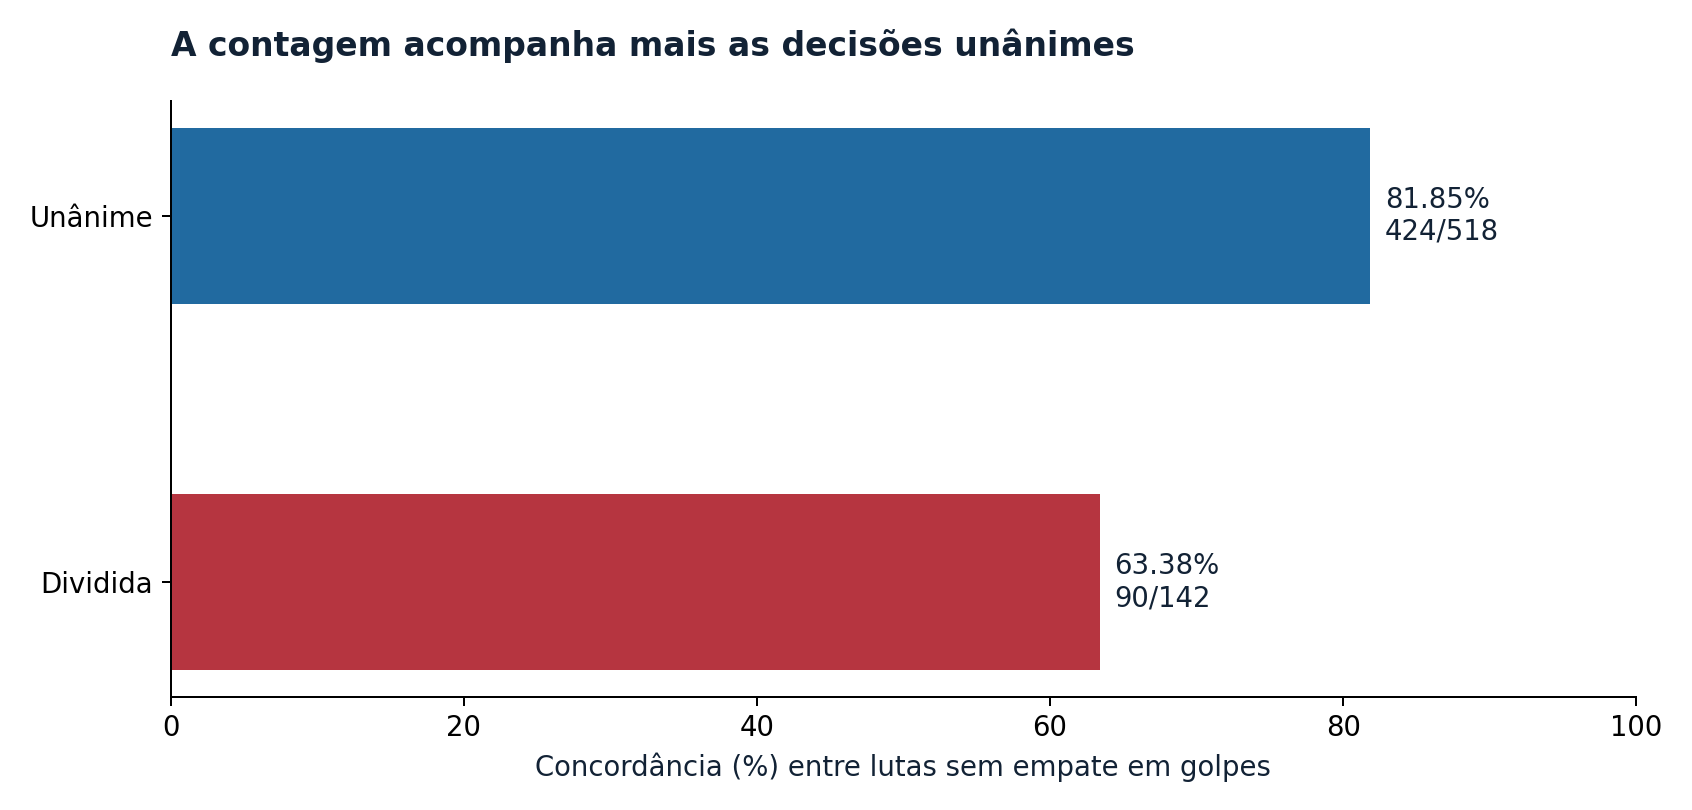

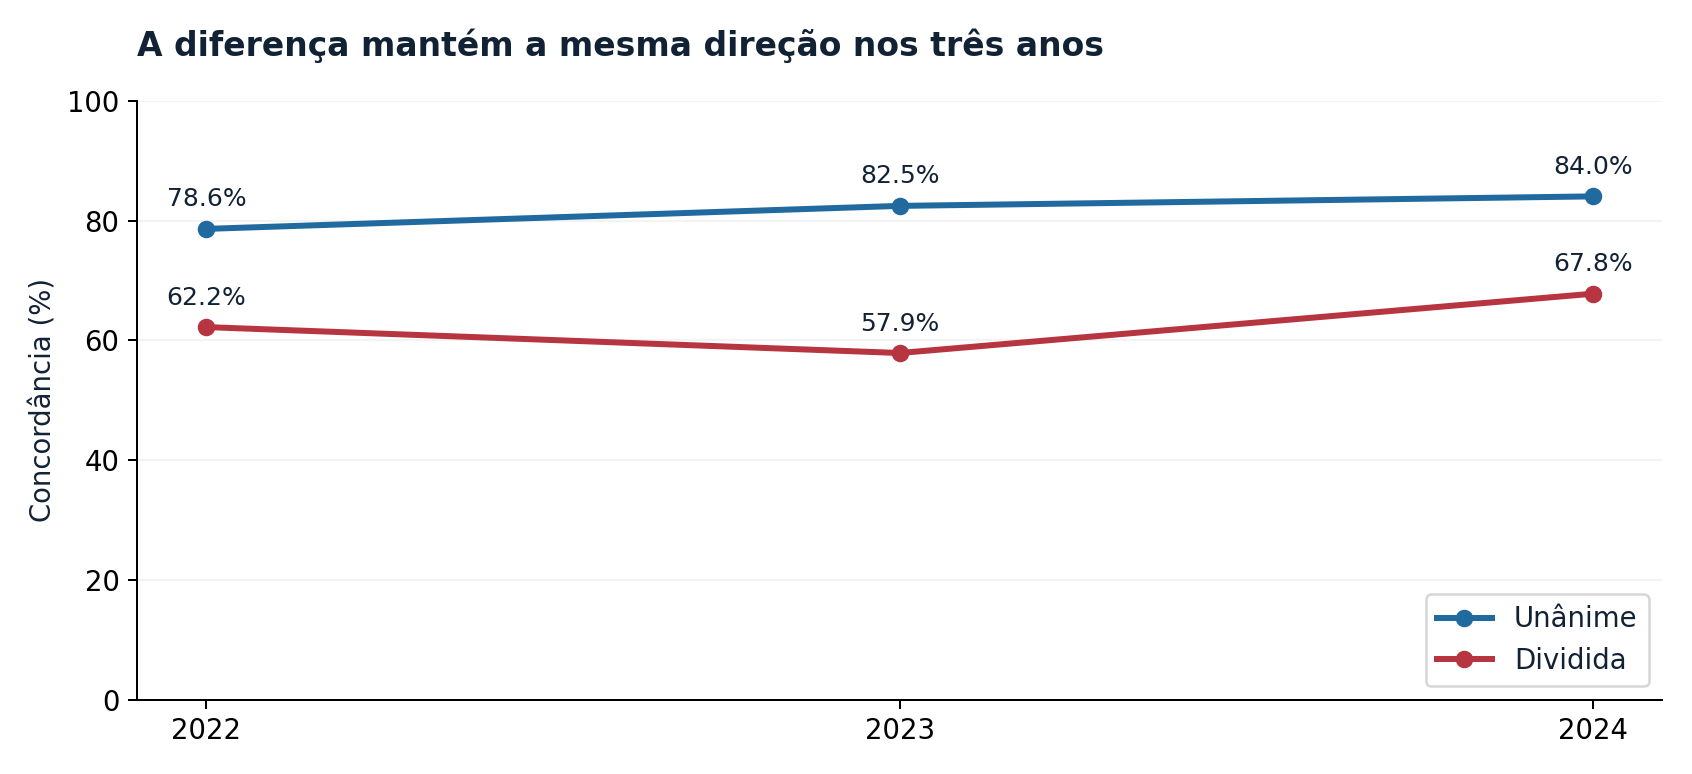

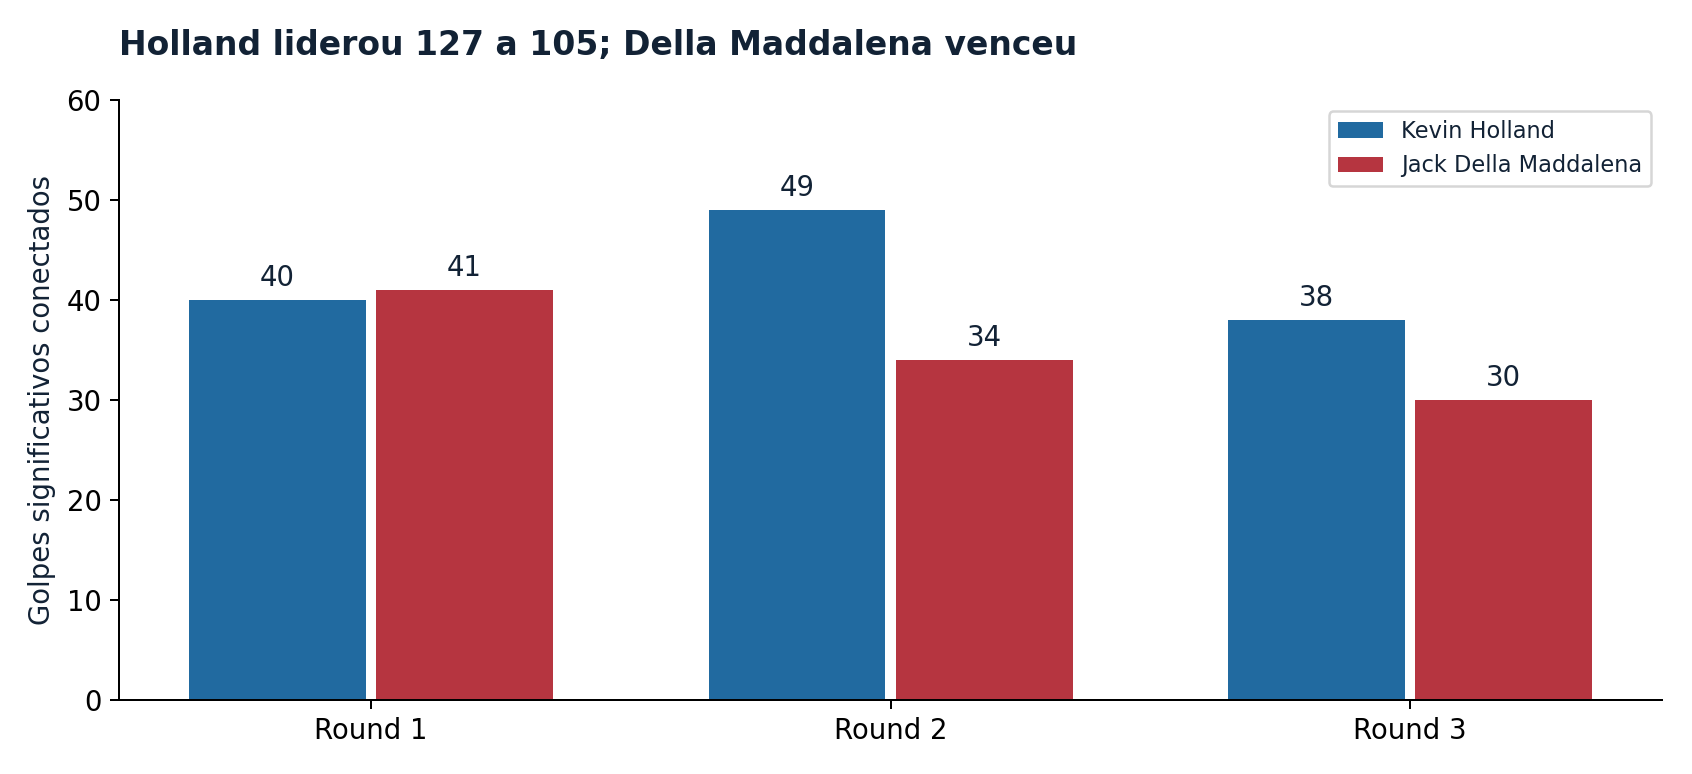

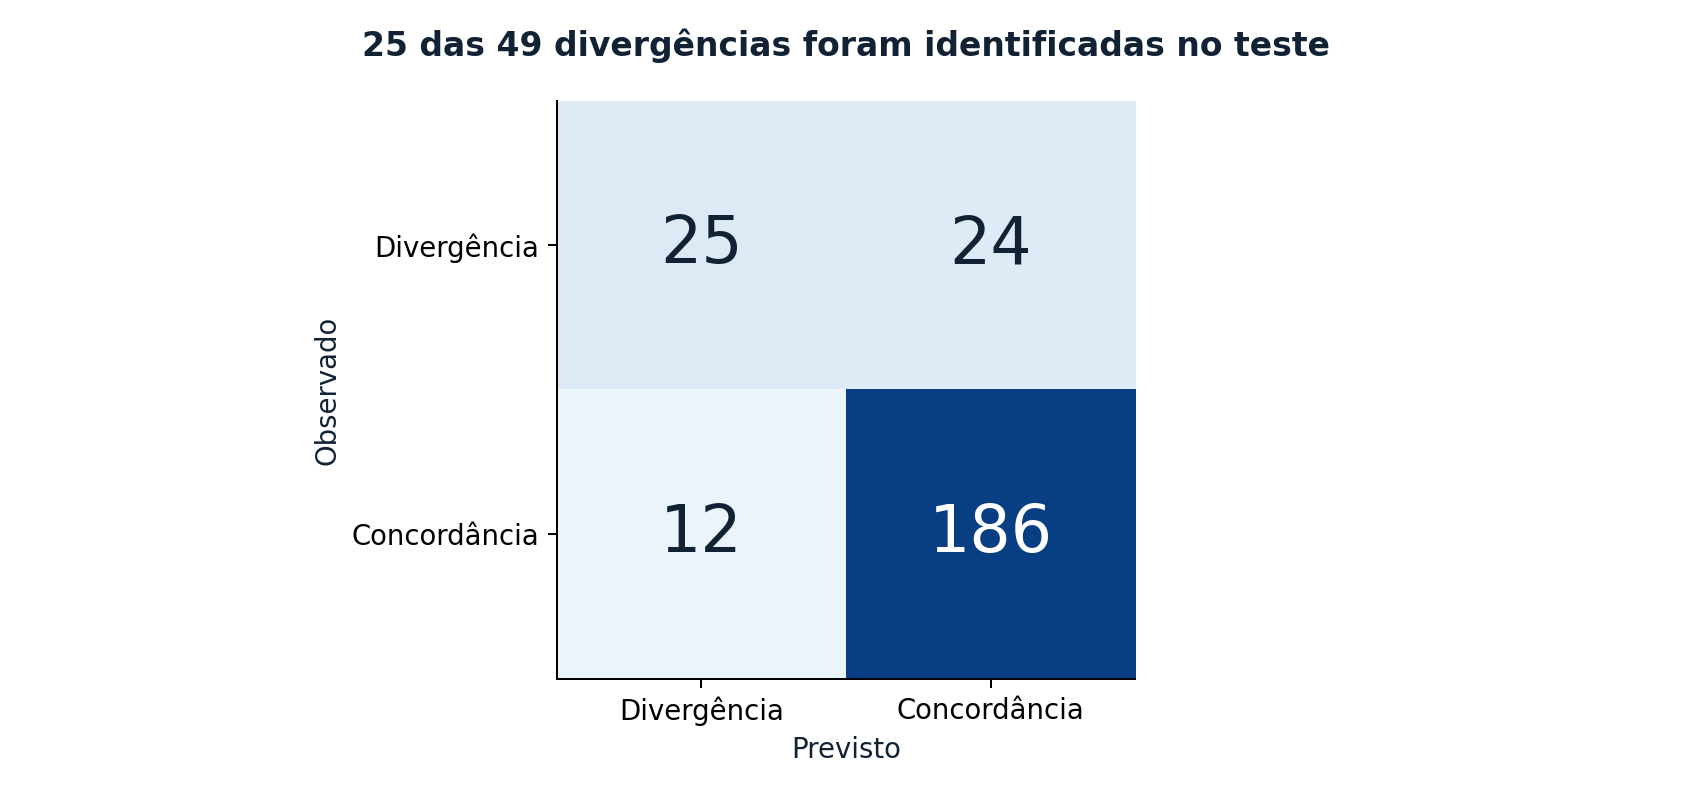

In [5]:
from src.visuals import build as build_visuals
from IPython.display import display, Image, HTML
page = build_visuals()
for name in ['concordance','years','holland','confusion']:
    display(Image(filename=str(ROOT / f'outputs/{name}.png'), width=850))

In [6]:
from src.conclusions import build as build_conclusions
from IPython.display import Markdown
conclusion_md, conclusion_html = build_conclusions()
display(Markdown(conclusion_md))

# Conclusão e respostas à Fase 1

## Resposta à pergunta central

Sim, liderar em golpes significativos conectados foi um indicador associado à vitória nas decisões analisadas. O líder venceu 514 das 660 lutas classificáveis (77,88%) e perdeu 146 (22,12%). Portanto, a liderança acompanhou a vitória na maioria dos casos, mas não garantiu o resultado. Esta conclusão descreve o UFC de 2022–2024, com três rounds completos e decisão unânime ou dividida.

## H1 recebe apoio descritivo

A concordância de 77,88% superou em 27,88 pontos percentuais a referência de 50% definida na Fase 1. Escolher o líder em golpes acertou mais resultados históricos que a referência de escolher aleatoriamente um dos dois atletas. A inferência exploratória complementar é apresentada separadamente e não muda o critério descritivo planejado.

## H2 recebe apoio descritivo

Nas decisões unânimes, o líder venceu 424/518 lutas (81,85%); nas divididas, 90/142 (63,38%). A diferença foi de 18,47 pontos percentuais a favor das unânimes. A mesma direção apareceu em 2022, 2023 e 2024: 16,39, 24,56, 16,25 pontos percentuais, respectivamente. A contagem, assim, acompanhou menos frequentemente o vencedor nas decisões divididas.

## Empates e robustez

As 665 lutas válidas incluem 5 empates em golpes, mantidos no painel e retirados apenas do denominador da concordância. A cobertura classificável foi 99,25%. Atribuir todos os empates aos extremos produz 77,29% a 78,05% de concordância no total válido, ainda acima de 50%. A direção de H2 também permanece nas atribuições extremas. Esses limites são uma análise de sensibilidade, não intervalos de confiança.

## Inferência complementar e seus limites

Sob o modelo de independência, o IC de 95% de Wilson global é 74,56%–80,88%. O teste binomial bilateral resulta em p=6.41e-49, e o teste exato de Fisher bilateral em p=6.87e-06, com razão de chances 2,61. O recorte reúne todos os confrontos elegíveis do snapshot, não uma amostra aleatória. Há atletas repetidos entre lutas; os testes não ajustam essa dependência nem fatores de confusão. ICs e p-valores são condicionais ao modelo de independência, não validação causal ou garantia de generalização.

## O que significa fazer diferença

Os resultados mostram utilidade da liderança em golpes para interpretar o resultado histórico. Não quantificam o efeito causal de um golpe adicional, o peso isolado da contagem no voto de cada juiz ou a probabilidade de uma luta futura. A base não contém os votos individuais por round; as divergências não demonstram erro ou viés de arbitragem. Também não se conclui que vencer a contagem de um round equivale a vencê-lo nos cartões.

## Aplicação para o analista de cobertura esportiva

Usar a contagem como evidência contextual, informando período, tipo de decisão e denominador. Nas divididas, 52/142 lutas (36,62%) tiveram vitória do atleta com menos golpes, o que exige cuidado ao interpretar apenas o total. O caso Holland × Della Maddalena ilustra uma dessas divergências; a conclusão provém do conjunto de lutas, não desse exemplo.

## Cumprimento dos objetivos da Fase 1

A base relacional foi integrada; concordâncias, divergências, empates e denominadores foram calculados; as decisões foram comparadas no conjunto e em cada ano; o painel permite consultar luta e rounds. O quarto objetivo específico permanece parcialmente atendido: as consultas foram reconciliadas internamente, mas a conferência dos campos das 12 fichas oficiais segue pendente por bloqueio de acesso. Os resultados referem-se ao espelho versionado e devem ser revistos se essa conferência identificar discrepâncias.

## Papel complementar do Analytics

O modelo com sete variáveis acrescenta uma análise preditiva retrospectiva exigida na Fase 2. Sua melhora agregada sobre a regra de escolher o líder não mede a contribuição isolada dos golpes significativos e não é a evidência usada para responder a H1 e H2. As hipóteses são respondidas pelas contagens e proporções acima.

## 5. Painéis interativos
As abas permitem consultar os KPIs, filtrar ano e tipo de decisão, conferir cada luta por round e reproduzir previsões de 2024. A aba do modelo tem seu próprio recorte fixo de teste. O arquivo `docs/index.html` também abre diretamente no navegador, sem servidor. No GitHub, abra este notebook no Colab e execute esta célula para usar as interações.

In [7]:
display(HTML(page))

<IPython.core.display.HTML object>

## 6. Testes e reconciliação
Inclui orientação W/L e L/W, valores ausentes, empate, filtro vazio, grade de rounds, igualdade entre SQL e Python e separação temporal.

In [8]:
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT/'tests'))
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()
# Evidência gerada pela própria execução, inclusive quando o autor usar o Colab.
import platform
from datetime import datetime, timezone
execution_evidence = {"executed_code_cells": 8, "errors": 0, "tests": test_result.testsRun, "executed_at": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(), "engine": "Google Colab" if "google.colab" in sys.modules else "IPython local", "platform_validation": "Execução hospedada" if "google.colab" in sys.modules else "Executado localmente; Colab hospedado não conferido"}
(ROOT/"outputs/notebook_execution.json").write_text(json.dumps(execution_evidence,ensure_ascii=False,indent=2))
print(execution_evidence)


{'executed_code_cells': 8, 'errors': 0, 'tests': 27, 'executed_at': '2026-11-26T01:10:27.254850+00:00', 'python': '3.12.14', 'engine': 'IPython local', 'platform_validation': 'Executado localmente; Colab hospedado não conferido'}


test_check_rejects_invalid_status (test_project.DatabaseSchema.test_check_rejects_invalid_status)
CHECK impede status fora de C/D/E (transação desfeita ao final). ... ok
test_foreign_key_rejects_orphan_round (test_project.DatabaseSchema.test_foreign_key_rejects_orphan_round)
FK impede round sem luta correspondente. ... ok
test_integrity_and_foreign_keys (test_project.DatabaseSchema.test_integrity_and_foreign_keys) ... ok
test_objects_exist (test_project.DatabaseSchema.test_objects_exist) ... ok
test_primary_key_rejects_duplicate_round (test_project.DatabaseSchema.test_primary_key_rejects_duplicate_round)
A chave composta (luta, atleta, round) impede duplicidade. ... ok
test_reference_queries_run (test_project.DatabaseSchema.test_reference_queries_run)
Todas as consultas de sql/consultas.sql executam e a auditoria Q7 retorna vazio. ... ok
test_row_counts_match_csv (test_project.DatabaseSchema.test_row_counts_match_csv) ... ok
test_empty_filter (test_project.EdgeCases.test_empty_filter)


## 7. Conferência das fontes e exportações
`outputs/source_checks.json` registra a tentativa de acesso às 12 fichas em 25/11/2026. Resposta HTTP 200 com verificação de navegador não foi contada como validação. Para repetir a coleta dessas páginas, execute `python -m src.source_check` e confronte os campos com os CSVs.

Artefatos: `data/processed/ufc.sqlite`, `bouts.csv`, `rounds.csv`, `outputs/predictions_2024.csv`, `inference.json`, `model_metrics.json`, `model.json`, `kpis.json`, `quality.json` e `docs/index.html`.

Fontes: [snapshot Greco1899](https://github.com/Greco1899/scrape_ufc_stats/tree/c742842f29466758fedc3906dbad28d6d320a8da), [UFCStats](http://ufcstats.com/statistics/events/completed?page=all), [Colab](https://research.google.com/colaboratory/faq.html), [scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html). Metodologia e avaliação seguem as Aulas 7 e 10. Os conceitos de indicadores, filtros e apresentação articulam as Aulas 6 e 9.

## 8. Conclusão final

## Resposta à pergunta central

Sim, liderar em golpes significativos conectados foi um indicador associado à vitória nas decisões analisadas. O líder venceu 514 das 660 lutas classificáveis (77,88%) e perdeu 146 (22,12%). Portanto, a liderança acompanhou a vitória na maioria dos casos, mas não garantiu o resultado. Esta conclusão descreve o UFC de 2022–2024, com três rounds completos e decisão unânime ou dividida.

## H1 recebe apoio descritivo

A concordância de 77,88% superou em 27,88 pontos percentuais a referência de 50% definida na Fase 1. Escolher o líder em golpes acertou mais resultados históricos que a referência de escolher aleatoriamente um dos dois atletas. A inferência exploratória complementar é apresentada separadamente e não muda o critério descritivo planejado.

## H2 recebe apoio descritivo

Nas decisões unânimes, o líder venceu 424/518 lutas (81,85%); nas divididas, 90/142 (63,38%). A diferença foi de 18,47 pontos percentuais a favor das unânimes. A mesma direção apareceu em 2022, 2023 e 2024: 16,39, 24,56, 16,25 pontos percentuais, respectivamente. A contagem, assim, acompanhou menos frequentemente o vencedor nas decisões divididas.

## Empates e robustez

As 665 lutas válidas incluem 5 empates em golpes, mantidos no painel e retirados apenas do denominador da concordância. A cobertura classificável foi 99,25%. Atribuir todos os empates aos extremos produz 77,29% a 78,05% de concordância no total válido, ainda acima de 50%. A direção de H2 também permanece nas atribuições extremas. Esses limites são uma análise de sensibilidade, não intervalos de confiança.

## Inferência complementar e seus limites

Sob o modelo de independência, o IC de 95% de Wilson global é 74,56%–80,88%. O teste binomial bilateral resulta em p=6.41e-49, e o teste exato de Fisher bilateral em p=6.87e-06, com razão de chances 2,61. O recorte reúne todos os confrontos elegíveis do snapshot, não uma amostra aleatória. Há atletas repetidos entre lutas; os testes não ajustam essa dependência nem fatores de confusão. ICs e p-valores são condicionais ao modelo de independência, não validação causal ou garantia de generalização.

## O que significa fazer diferença

Os resultados mostram utilidade da liderança em golpes para interpretar o resultado histórico. Não quantificam o efeito causal de um golpe adicional, o peso isolado da contagem no voto de cada juiz ou a probabilidade de uma luta futura. A base não contém os votos individuais por round; as divergências não demonstram erro ou viés de arbitragem. Também não se conclui que vencer a contagem de um round equivale a vencê-lo nos cartões.

## Aplicação para o analista de cobertura esportiva

Usar a contagem como evidência contextual, informando período, tipo de decisão e denominador. Nas divididas, 52/142 lutas (36,62%) tiveram vitória do atleta com menos golpes, o que exige cuidado ao interpretar apenas o total. O caso Holland × Della Maddalena ilustra uma dessas divergências; a conclusão provém do conjunto de lutas, não desse exemplo.

## Cumprimento dos objetivos da Fase 1

A base relacional foi integrada; concordâncias, divergências, empates e denominadores foram calculados; as decisões foram comparadas no conjunto e em cada ano; o painel permite consultar luta e rounds. O quarto objetivo específico permanece parcialmente atendido: as consultas foram reconciliadas internamente, mas a conferência dos campos das 12 fichas oficiais segue pendente por bloqueio de acesso. Os resultados referem-se ao espelho versionado e devem ser revistos se essa conferência identificar discrepâncias.

## Papel complementar do Analytics

O modelo com sete variáveis acrescenta uma análise preditiva retrospectiva exigida na Fase 2. Sua melhora agregada sobre a regra de escolher o líder não mede a contribuição isolada dos golpes significativos e não é a evidência usada para responder a H1 e H2. As hipóteses são respondidas pelas contagens e proporções acima.